# More efficient plants, less electricity?
## Assignment 2 · Evaluating an energy-consulting programme · Python solution

*Economic Analysis for Data Scientists, Unit 3 (Pau Milán, BSE).*

The government offered energy consulting to manufacturing plants, hoping to reduce electricity use. We evaluate the pilot with **480 plants observed for 16 months** (month −3 to 12; consulting starts in month 1). Half the plants in each sector × staffing-review cohort were randomly assigned to consulting.

**Our route:** explore the records → describe the pattern → evaluate with the randomisation → **stop for production theory** → recover the efficiency gain → test the mechanism on held-out months → use the model for counterfactuals and advice.

| | |
|---|---|
| Language | Python 3 (pandas, numpy, matplotlib). The handout asks for R; the group confirmed Python is accepted. |
| Data | `data/energy_firms.csv`, read with a relative path. Run all cells from top to bottom. |
| Outputs | Every figure and table is also saved in `outputs/figures` and `outputs/tables`. |
| Optional work | Question 9 and the electricity-levy extension of Question 7 are included and marked *optional*. |

**Group contributions**

| Member | Thread | Questions | Main outputs |
|---|---|---|---|
| Cintia | Model and policy | Q4, Q7, Q8 (and the optional levy extension and Q9) | Theory diagrams, follow-up simulation table, policy briefing |
| Gshan | Efficiency and predictions | Q5, Q6(a), Q6(b) | Efficiency-gain estimate with CI, predicted-vs-observed plots, output-vs-electricity criterion |
| Kapil | Evaluation and firm differences | Q3, Q6(c), Q6(d), notebook assembly | Effects table and figure, heterogeneity figure, timing figure by review month; final run from a clean kernel |

Questions 1–2 and the shared model equations (Q4) were done by the whole group together. All three members reviewed the briefing against their own numbers.

### Set-up and helpers
Run once. The helpers display and save figures and tables; they do not estimate anything.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats as st
from IPython.display import display, HTML

pd.set_option("display.width", 130, "display.max_columns", 30, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False})

DATA = "data/energy_firms.csv"
if not os.path.exists(DATA):
    raise FileNotFoundError("Open this notebook beside its data/ folder (data/energy_firms.csv).")
os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/tables", exist_ok=True)

BLUE, ORANGE, GREEN, PURPLE, GREY = "#246B87", "#D77D30", "#368574", "#825493", "#737B83"
GROUP_COL = {0: BLUE, 1: ORANGE}
GROUP_LAB = {0: "Control", 1: "Consulting (treated)"}
COHORT_COL = {4: "#F2B880", 6: ORANGE, 8: "#8A3B12"}


def figure(fig, name):
    """Save the figure in outputs/figures and show it."""
    fig.tight_layout()
    fig.savefig(f"outputs/figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def table_out(x, name):
    """Save the table in outputs/tables and display it."""
    x.to_csv(f"outputs/tables/{name}.csv")
    display(x)


def diff_ci(data, col):
    """Treated − control difference in plant means, with a 95% CI. Plants are the units."""
    t = data.loc[data.treated == 1, col].dropna()
    c = data.loc[data.treated == 0, col].dropna()
    d = t.mean() - c.mean()
    se = np.sqrt(t.var() / len(t) + c.var() / len(c))
    return pd.Series({"treated": t.mean(), "control": c.mean(), "effect": d, "se": se,
                      "ci_low": d - 1.96 * se, "ci_high": d + 1.96 * se,
                      "n_treated": len(t), "n_control": len(c)})


def mean_ci(x):
    """Mean of plant-level values with a 95% CI."""
    x = pd.Series(x).dropna()
    se = x.std() / np.sqrt(len(x))
    return pd.Series({"mean": x.mean(), "ci_low": x.mean() - 1.96 * se,
                      "ci_high": x.mean() + 1.96 * se, "n_plants": len(x)})


def stars(p):
    return "***" if p < .01 else "**" if p < .05 else "*" if p < .10 else ""


def reg_table(panels, columns, name, coef="treated", coef_label="Treated", below=None, notes=""):
    """Regression table in the style of Stata's esttab: one model per column, robust SE in parentheses.

    panels: list of (panel title or None, list of fitted models, decimals).
    coef: one coefficient name, or a dict {name: row label} for several rows (blank where a model omits it).
    below: {row label: list of cell strings}. Shows the table and saves a plain version in outputs/tables."""
    coefs = coef if isinstance(coef, dict) else {coef: coef_label}
    td = 'style="padding:3px 14px; text-align:center"'
    tl = 'style="padding:3px 14px; text-align:left"'
    ncol = len(columns) + 1
    html = ['<table style="border-collapse:collapse; border-top:2px solid; border-bottom:2px solid; margin:6px 0">',
            f'<tr style="border-bottom:1px solid"><th {tl}></th>'
            + "".join(f"<th {td}>({i + 1})<br>{c}</th>" for i, c in enumerate(columns)) + "</tr>"]
    plain = {}
    for title, models, dec in panels:
        if title:
            html.append(f'<tr><td colspan="{ncol}" {tl}><b>{title}</b></td></tr>')
        for cname, clab in coefs.items():
            b = [f"{m.params[cname]:,.{dec}f}{stars(m.pvalues[cname])}" if cname in m.params else "" for m in models]
            se = [f"({m.bse[cname]:,.{dec}f})" if cname in m.params else "" for m in models]
            html.append(f"<tr><td {tl}>{clab}</td>" + "".join(f"<td {td}>{x}</td>" for x in b) + "</tr>")
            html.append(f"<tr><td {tl}></td>" + "".join(f"<td {td}>{x}</td>" for x in se) + "</tr>")
            plain[(title or "", clab)], plain[(title or "", clab + " (se)")] = b, se
    for i, (lab, cells) in enumerate((below or {}).items()):
        top = "border-top:1px solid; " if i == 0 else ""
        html.append(f'<tr style="{top}"><td {tl}>{lab}</td>' + "".join(f"<td {td}>{x}</td>" for x in cells) + "</tr>")
        plain[("", lab)] = cells
    html.append(f'<tr style="border-top:1px solid"><td colspan="{ncol}" style="padding:3px 14px; text-align:left; font-size:85%">'
                f'{notes} * p&lt;0.10, ** p&lt;0.05, *** p&lt;0.01.</td></tr></table>')
    pd.DataFrame(plain, index=columns).T.to_csv(f"outputs/tables/{name}.csv")
    display(HTML("".join(html)))


def balance_table(data, panels, name, caption=""):
    """Balance table in the style of Stata's iebaltab: N and mean by group, difference (treated − control)
    with stars and Welch t-test p-value, and a joint F-test that the variables do not predict treatment.

    panels: list of (panel title, {column: (row label, decimals)}). Shows the table and saves it in outputs/tables."""
    td = 'style="padding:3px 12px; text-align:right"'
    tl = 'style="padding:3px 12px; text-align:left"'
    html = ['<table style="border-collapse:collapse; border-top:2px solid; border-bottom:2px solid; margin:6px 0">',
            f'<caption style="text-align:left; font-weight:bold; padding-bottom:4px">{caption}</caption>',
            f'<tr><th {tl}></th><th colspan="2" style="text-align:center; border-bottom:1px solid">Control</th>'
            f'<th colspan="2" style="text-align:center; border-bottom:1px solid">Treated</th>'
            f'<th colspan="2" style="text-align:center; border-bottom:1px solid">Difference (T − C)</th></tr>',
            f'<tr style="border-bottom:1px solid"><th {tl}>Variable</th>'
            + "".join(f"<th {td}>{x}</th>" for x in ["N", "Mean", "N", "Mean", "Diff.", "p-value"]) + "</tr>"]
    rows, cols = [], []
    for title, variables in panels:
        html.append(f'<tr style="border-bottom:1px solid"><td colspan="7" {tl}><b>{title}</b></td></tr>')
        for v, (lab, dec) in variables.items():
            c, t = data.loc[data.treated == 0, v], data.loc[data.treated == 1, v]
            p = st.ttest_ind(t, c, equal_var=False).pvalue
            cells = [len(c), f"{c.mean():,.{dec}f}", len(t), f"{t.mean():,.{dec}f}",
                     f"{t.mean() - c.mean():,.{dec}f}{stars(p)}", f"{p:.3f}"]
            html.append(f"<tr><td {tl}>{lab}</td>" + "".join(f"<td {td}>{x}</td>" for x in cells) + "</tr>")
            rows.append([title, lab] + cells)
            cols.append(v)
    joint = smf.ols("treated ~ " + " + ".join(cols), data=data).fit()
    html.append(f'<tr style="border-top:1px solid"><td colspan="7" style="padding:3px 12px; text-align:left; font-size:85%">'
                f"Joint F-test that no variable predicts treatment: F({int(joint.df_model)}, {int(joint.df_resid)}) = "
                f"{joint.fvalue:.2f}, p = {joint.f_pvalue:.3f}. Per-variable p-values: two-sample t-test with unequal "
                f"variances. * p&lt;0.10, ** p&lt;0.05, *** p&lt;0.01.</td></tr></table>")
    pd.DataFrame(rows, columns=["panel", "variable", "N control", "mean control", "N treated",
                                "mean treated", "difference", "p-value"]).to_csv(f"outputs/tables/{name}.csv", index=False)
    display(HTML("".join(html)))

# 1. Explore electricity use before and after consulting

**TLDR of Section 1**
* **The data are clean and the experiment was set up as described.** 480 plants observed for 16 months, with 240 treated and 240 control plants.
* **Treated and control plants are comparable.** Treated plants chose slightly more output and labour before the programme, but prices, the electricity share and all variables jointly are balanced.
* **Electricity falls, then rises.** Treated plants cut electricity by about a quarter when consulting starts, but in the medium run they use about 10% more than before.
* **Plants produce more.** Output and labour do not move at first, then rise by about 22% and 49%. Each unit of output still needs less electricity, but plants make more units.

### 1.1 The setting

480 manufacturing plants, half in **Textiles** and half in **Chemicals**. Each row of the data is one plant in one month, from month −3 to month 12. For each plant we observe three quantities it chooses every month and three prices it faces:

| Symbol | Variable | What it is | Units |
|---|---|---|---|
| $q$ | `output` | Quantity produced | batches per month (a batch is the standard unit of output) |
| $L$ | `labor` | Paid labour | blocks of 100 worker-hours per month |
| $E$ | `electricity` | Electricity used | MWh per month |
| $p$ | `output_price` | Price the plant gets per unit of output | CU per batch |
| $w$ | `wage` | Wage per labour block | CU per block |
| $c$ | `energy_price` | Price per MWh of electricity | CU per MWh |

* **Treatment:** in each sector × review-month group, half of the plants were randomly chosen to receive energy consulting, starting in **month 1**.
* **Staffing rule:** from month 1, each plant's paid labour is fixed until its staffing review (month 4, 6 or 8). After the review, labour can change. Electricity can change at any time. Control plants follow the same rule.

**Key periods.** We split the 16 months by what plants can adjust:

| Period | Months | What happens |
|---|---|---|
| **Baseline** | −3 to 0 | Before consulting; plants choose all inputs freely |
| **Short run** | 1 to 3 | Consulting has started; labour is fixed for every plant |
| **Transition** | 4 to 8 | Plants have their staffing reviews (in month 4, 6 or 8) |
| **Medium run** | 9 to 12 | All plants have had their review; labour is free again |

We use the short run and the medium run to measure effects, because within each of them all plants are in the same situation.

### 1.2 Data audit

This section checks that the data and the experiment are as the handout describes. Namely, we check:
* Balanced panel
* The experiment was implemented as described
* Prices are fixed for each plant
* Pre-treatment characteristics are comparable

Conclusion: we found no issues. The panel is balanced and clean, the experiment follows the design, prices never change within a plant, and treated and control plants are comparable.

##### 1.2.1 Balanced panel and experimental design

In [2]:
df = pd.read_csv(DATA).sort_values(["firm_id", "month"]).reset_index(drop=True)
qty = ["output", "labor", "electricity"]
prices = ["output_price", "wage", "energy_price"]
by_firm = df.groupby("firm_id")

checks = pd.Series({
    "plant-month rows": len(df),
    "plants": df.firm_id.nunique(),
    "months observed": f"{df.month.min()} to {df.month.max()} ({df.month.nunique()} months)",
    "plants with all 16 months": int((by_firm.size() == 16).sum()),
    "duplicate plant-months": int(df.duplicated(["firm_id", "month"]).sum()),
    "missing values": int(df.isna().sum().sum()),
    "non-positive quantities": int((df[qty] <= 0).sum().sum()),
    "plants whose prices change": int((by_firm[prices].nunique() > 1).any(axis=1).sum()),
    "plants whose sector/treated/adjust_month change": int(
        (by_firm[["sector", "treated", "adjust_month"]].nunique() > 1).any(axis=1).sum()),
}, name="value").to_frame()
assert checks.loc["plants", "value"] == 480 and checks.loc["duplicate plant-months", "value"] == 0
assert checks.loc["missing values", "value"] == 0 and checks.loc["plants whose prices change", "value"] == 0
table_out(checks, "01_panel_checks")

firms = df.drop_duplicates("firm_id").set_index("firm_id")
design = pd.crosstab([firms.sector, firms.adjust_month], firms.treated.map(GROUP_LAB), margins=True)
table_out(design, "01_design")

# Does labor_adjustable follow the institutional rule?
post = df[df.month >= 1]
rule_ok = (post.labor_adjustable == (post.month >= post.adjust_month)).all()
print("Months 1-12: labor_adjustable == (month >= adjust_month) for every row:", rule_ok)
print("Months -3..0: share coded labor_adjustable = 1:", df.loc[df.month <= 0, "labor_adjustable"].mean())

,value
plant-month rows,7680
plants,480
months observed,-3 to 12 (16 months)
plants with all 16 months,480
duplicate plant-months,0
missing values,0
non-positive quantities,0
plants whose prices change,0
plants whose sector/treated/adjust_month change,0


treated                 Consulting (treated)  Control  All
sector    adjust_month                                    
Chemicals 4                               40       40   80
          6                               40       40   80
          8                               40       40   80
Textiles  4                               40       40   80
          6                               40       40   80
          8                               40       40   80
All                                      240      240  480

Months 1-12: labor_adjustable == (month >= adjust_month) for every row: True
Months -3..0: share coded labor_adjustable = 1: 1.0


Every plant is observed in all 16 months, with no missing values, duplicates or zeros. There are exactly 40 treated and 40 control plants in every sector × review-month group, and the staffing rule (`labor_adjustable`) is coded as described.

##### 1.2.2 Prices are fixed for each plant

Each plant has its own $p$, $w$ and $c$ (480 different values of each), and they never change over the 16 months.

> **Important for the rest of the analysis:** prices are fixed plant characteristics; quantities are the plant's decisions. So prices cannot explain why $q$, $L$ or $E$ change after month 1: those changes must come from consulting or from the staffing rule. Differences in prices *across* plants will matter for how strongly each plant responds (Q4, Q6(c)).

##### 1.2.3 Pre-treatment characteristics are comparable

**Objective:** to check that the control group is a good comparison for the treated group, we compare the two groups before the programme. We use each plant's average over the baseline months, which also smooths out small recording errors.

In [3]:
def window(a, b, var):
    return df[df.month.between(a, b)].groupby("firm_id")[var].mean()

WINDOWS = {"0": (-3, 0), "1": (1, 3), "2": (9, 12)}   # 0 = baseline, 1 = short run, 2 = medium run
P = firms[["sector", "treated", "adjust_month", "output_price", "wage", "energy_price"]].copy()
P.columns = ["sector", "treated", "adjust_month", "p", "w", "c"]
for h, (a, b) in WINDOWS.items():
    P["q" + h], P["L" + h], P["E" + h] = window(a, b, "output"), window(a, b, "labor"), window(a, b, "electricity")

# Baseline characteristics used throughout
P["labor_per_mwh0"] = P.L0 / P.E0                          # L/E: later interpreted as eta
P["energy_share0"] = P.c * P.E0 / (P.w * P.L0 + P.c * P.E0)  # electricity share of variable cost
P["profit0"] = P.p * P.q0 - P.w * P.L0 - P.c * P.E0         # operating profit, CU per month

# (1) Balance: treated vs control before the programme (one observation per plant)
balance_table(P, [
    ("Panel A: Quantities at baseline (monthly mean, months −3 to 0)",
     {"q0": ("Output q (batches)", 1), "L0": ("Labour L (blocks of 100 h)", 1), "E0": ("Electricity E (MWh)", 0)}),
    ("Panel B: Prices (constant over time)",
     {"p": ("Output price p (CU per batch)", 0), "w": ("Wage w (CU per block)", 0), "c": ("Electricity price c (CU per MWh)", 1)}),
    ("Panel C: Cost structure at baseline",
     {"energy_share0": ("Electricity share of variable cost s0", 3)})],
    name="01_baseline_balance", caption="Balance before the programme, all plants")

# (2) Electricity share by sector: it matters later (Q4, Q6(c))
print("Median electricity share s0:", P.groupby("sector").energy_share0.median().round(2).to_dict(),
      "| 10th–90th percentile, all plants:", P.energy_share0.quantile([.1, .9]).round(2).tolist(),
      "| median electricity price c:", P.groupby("sector").c.median().round(0).to_dict())

# (3) Recording noise: month-to-month variation within a plant during the baseline
base = df[df.month <= 0]
noise_cv = (base.groupby("firm_id")[qty].std() / base.groupby("firm_id")[qty].mean() * 100).median()
print("Median within-plant month-to-month variation at baseline (%):", noise_cv.round(1).to_dict())

Median electricity share s0: {'Chemicals': 0.73, 'Textiles': 0.67} | 10th–90th percentile, all plants: [0.48, 0.85] | median electricity price c: {'Chemicals': 153.0, 'Textiles': 119.0}
Median within-plant month-to-month variation at baseline (%): {'output': 1.6, 'labor': 1.2, 'electricity': 1.8}


We can make the following observations:
* **Individually, treated plants chose slightly more output and labour before the programme**, about 5–8% more (p = 0.05 and 0.04). This is a chance difference in plant size, not a failure of the randomisation: output, labour and electricity all measure size and move together.
* **On all other variables, and jointly, the two groups are comparable.** Prices, the electricity share and electricity use are balanced, and all variables together do not predict who was treated (joint F-test p = 0.45).
* **Therefore**, from here on we compare each plant with **its own baseline**, which removes any permanent size difference.
* **Electricity is a large share of costs:** about 70% of variable costs at the median, and more in Chemicals (0.73) than in Textiles (0.67), because Chemicals plants pay more per MWh. This will explain which plants respond most.

### 1.3 Electricity use by month, treated vs control

**Objective:** to see how electricity changes once consulting starts, we plot average electricity per plant in each month for the treated and control groups. The dashed lines mark when each period starts.


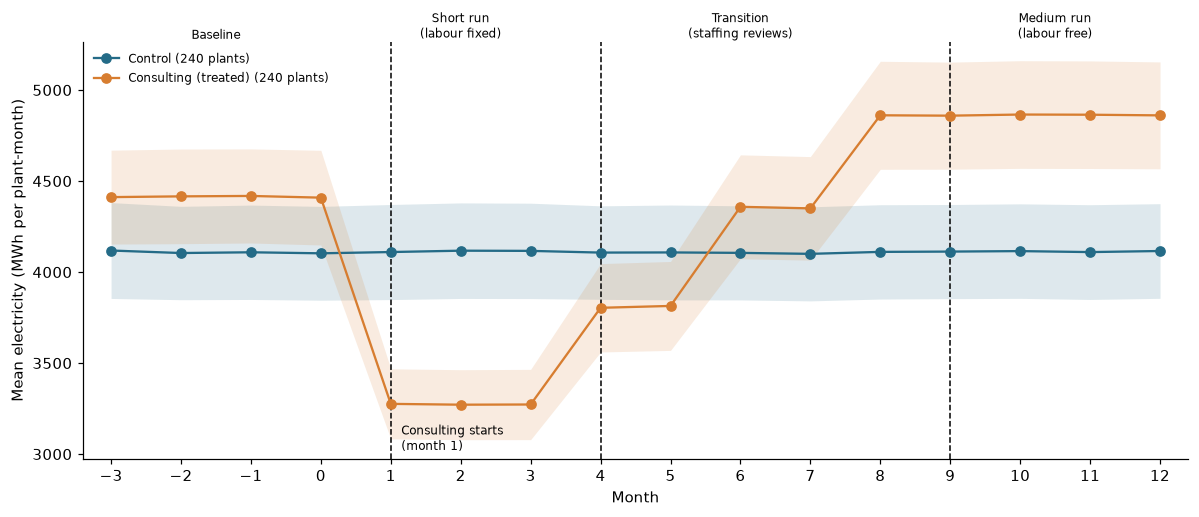

In [4]:
months = np.arange(-3, 13)
PERIODS = [(-3, 0, "Baseline"), (1, 3, "Short run\n(labour fixed)"),
           (4, 8, "Transition\n(staffing reviews)"), (9, 12, "Medium run\n(labour free)")]


def mark_periods(a, labels=True):
    """Dashed line where each period after the baseline starts (months 1, 4, 9), with period labels on top."""
    for lo, hi, lab in PERIODS:
        if lo > 0:
            a.axvline(lo, color="black", ls="--", lw=1)
        if labels:
            a.text((lo + hi) / 2, 1.0, lab, transform=a.get_xaxis_transform(), ha="center", va="bottom", fontsize=8)
    a.set_xlim(-3.4, 12.4)


# Mean electricity per plant in each month, treated vs control, with 95% CI (plants as units)
fig, ax = plt.subplots(figsize=(11, 4.8))
mark_periods(ax)
for g in (0, 1):
    s = df[df.treated == g].groupby("month").electricity
    m, se = s.mean(), s.std() / np.sqrt(s.count())
    ax.plot(months, m, "o-", color=GROUP_COL[g], label=f"{GROUP_LAB[g]} (240 plants)")
    ax.fill_between(months, m - 1.96 * se, m + 1.96 * se, color=GROUP_COL[g], alpha=.15, lw=0)
ax.annotate("Consulting starts\n(month 1)", xy=(1, 3000), xytext=(1.15, 3000), fontsize=8, va="bottom")
ax.set(xlabel="Month", ylabel="Mean electricity (MWh per plant-month)", xticks=months)
ax.legend(fontsize=8, loc="upper left")
figure(fig, "01_electricity_by_month")

We can make the following observations:
* **Control plants stay flat** at about 4,100 MWh per month: nothing else moves electricity over time.
* **Treated plants cut electricity by about a quarter as soon as consulting starts**, from about 4,400 to 3,300 MWh, and stay there while labour is fixed.
* **But the saving does not last.** During the transition, electricity of treated plants rises in steps, and in the medium run they use about **10% more** than before the programme.

### 1.4 Output, labour and electricity per unit of output

**Objective:** to understand why electricity rises again, we look at what happens to production at the same time. Each plant's baseline is set to 100.

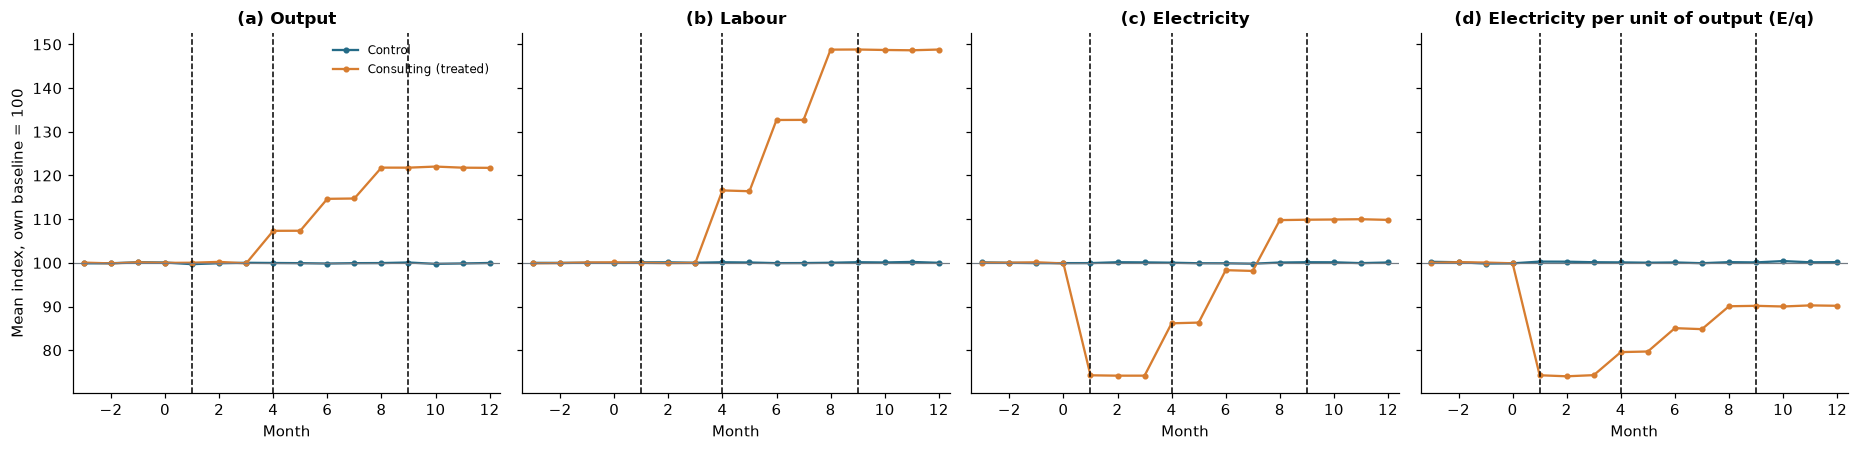

In [5]:
# Variables relative to each plant's baseline, used here and in later sections
df = df.merge(P[["E0", "L0", "q0"]], left_on="firm_id", right_index=True)
df["e_index"] = 100 * df.electricity / df.E0          # each plant's own baseline = 100
df["dlogE"] = np.log(df.electricity / df.E0)
df["dlogL"] = np.log(df.labor / df.L0)
df["dlogq"] = np.log(df.output / df.q0)

# Output, labour, electricity and electricity per unit of output, each plant indexed to its own baseline = 100
df["Eq_index"] = 100 * (df.electricity / df.output) / (df.E0 / df.q0)
panels = [("output", "q0", "(a) Output"), ("labor", "L0", "(b) Labour"),
          ("electricity", "E0", "(c) Electricity"), (None, None, "(d) Electricity per unit of output (E/q)")]
fig, ax = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for a, (var, base, title) in zip(ax, panels):
    y = df.Eq_index if var is None else 100 * df[var] / df[base]
    for g in (0, 1):
        a.plot(months, y[df.treated == g].groupby(df.month).mean(), "o-", ms=3, color=GROUP_COL[g], label=GROUP_LAB[g])
    mark_periods(a, labels=False)
    a.axhline(100, color=GREY, lw=.8)
    a.set(title=title, xlabel="Month")
ax[0].set_ylabel("Mean index, own baseline = 100")
ax[0].legend(fontsize=8)
figure(fig, "01_inputs_output_by_month")

We can make the following observations:
* **In the short run, output and labour do not move.** Plants produce the same with about a quarter less electricity.
* **From month 4, treated plants expand:** by the medium run they produce about 22% more and use about 49% more labour.
* **Electricity per unit of output stays below baseline**, about −10% in the medium run. Each unit needs less electricity, but plants make more units, so total electricity goes up.

This raises the question for the rest of the assignment: **why does electricity end up higher, if the programme was meant to reduce it?** We answer it with the theory in Q4.

# 2. What does the time pattern tell you?

**TLDR of Section 2**
* **A single average hides what happened.** Over months 1–12 treated plants use only about 5% less electricity, but this mixes a 26% saving in the short run with a 9% increase in the medium run.
* **Each plant jumps once, in its own review month.** The step-by-step rise of the average comes from three groups of plants jumping in months 4, 6 and 8.
* **Chemicals plants rebound more than Textiles plants**, although both save the same at first.

### 2.1 One average vs the average in each period

**Objective:** to check whether one number for the whole post-programme period describes the effect well, we compare it with the average in each period (change in log electricity from each plant's baseline, × 100 ≈ % change).

In [6]:
# Single post-programme average vs the average in each period
P["dlogE_sr"] = np.log(P.E1 / P.E0)      # short run vs baseline, used in later sections
P["dlogE_mr"] = np.log(P.E2 / P.E0)      # medium run vs baseline, used in later sections
phases = {"Short run (months 1–3)": (1, 3), "Transition (months 4–8)": (4, 8),
          "Medium run (months 9–12)": (9, 12), "Single average (months 1–12)": (1, 12)}
rows = {}
for lab, (a, b) in phases.items():
    # Same definition as in Q3: log of the plant's window mean relative to its baseline mean
    z = np.log(window(a, b, "electricity") / P.E0)
    rows[lab] = {"Control": z[P.treated == 0].mean(), "Treated": z[P.treated == 1].mean()}
phase_tab = 100 * pd.DataFrame(rows).T
phase_tab["Difference (treated − control)"] = phase_tab.Treated - phase_tab.Control
table_out(phase_tab.round(1), "02_phases")

,Control,Treated,Difference (treated − control)
Short run (months 1–3),0.1,-30.0,-30.1
Transition (months 4–8),-0.1,-5.3,-5.3
Medium run (months 9–12),0.1,9.0,9.0
Single average (months 1–12),0.0,-5.4,-5.4


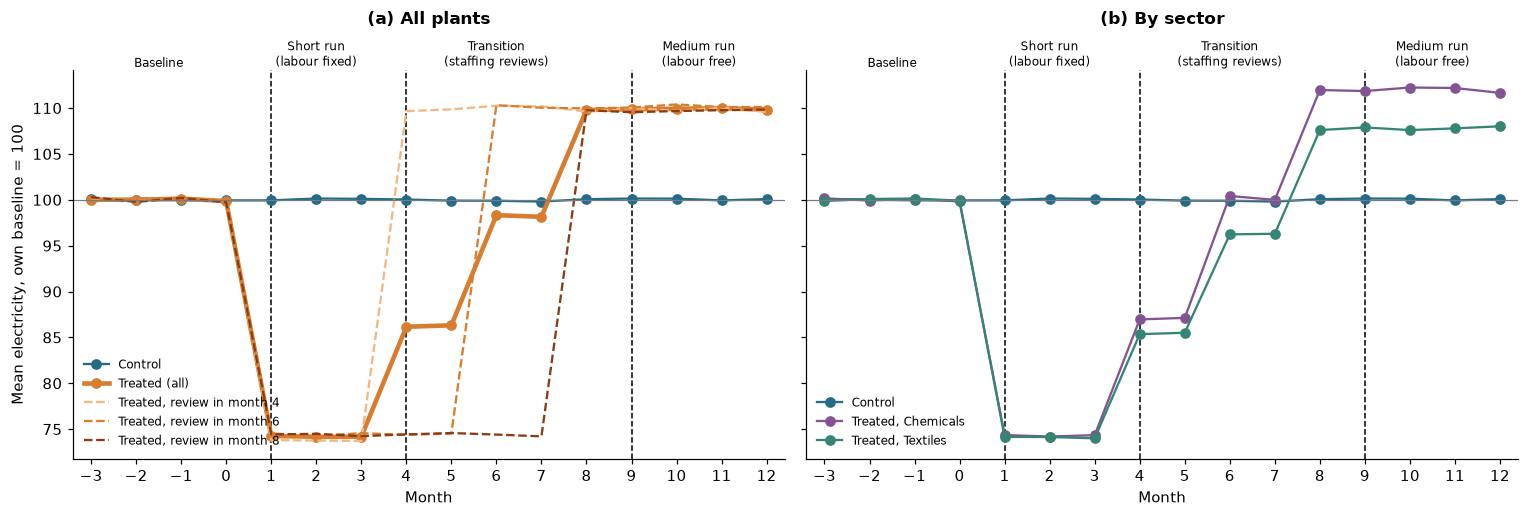

Treated plants above their baseline in the medium run: 83%
Medium-run change vs baseline (× 100), treated, by sector: {'Chemicals': 11.0, 'Textiles': 7.1}


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
ctrl = df[df.treated == 0].groupby("month").e_index.mean()

# (a) Aggregate: treated vs control, with the three staffing-review cohorts
mark_periods(ax[0])
ax[0].plot(months, ctrl, "o-", color=BLUE, label="Control")
ax[0].plot(months, df[df.treated == 1].groupby("month").e_index.mean(), "o-", color=ORANGE, lw=3, label="Treated (all)")
for m, col in COHORT_COL.items():
    z = df[(df.treated == 1) & (df.adjust_month == m)].groupby("month").e_index.mean()
    ax[0].plot(z.index, z, "--", color=col, label=f"Treated, review in month {m}")
ax[0].set_title("(a) All plants", pad=30)
ax[0].set(xlabel="Month", ylabel="Mean electricity, own baseline = 100")
ax[0].legend(fontsize=8, loc="lower left")

# (b) By sector: treated plants in each sector vs control
mark_periods(ax[1])
ax[1].plot(months, ctrl, "o-", color=BLUE, label="Control")
for sec, col in [("Chemicals", PURPLE), ("Textiles", GREEN)]:
    z = df[(df.treated == 1) & (df.sector == sec)].groupby("month").e_index.mean()
    ax[1].plot(months, z, "o-", color=col, label=f"Treated, {sec}")
ax[1].set_title("(b) By sector", pad=30)
ax[1].set(xlabel="Month")
ax[1].legend(fontsize=8, loc="lower left")
for a in ax:
    a.axhline(100, color=GREY, lw=.8)
    a.set_xticks(months)
figure(fig, "02_time_pattern")

T = P[P.treated == 1]
print(f"Treated plants above their baseline in the medium run: {100 * (T.dlogE_mr > 0).mean():.0f}%")
print("Medium-run change vs baseline (× 100), treated, by sector:", (100 * T.groupby("sector").dlogE_mr.mean()).round(1).to_dict())

We can make the following observations:
* **One average is misleading.** Over months 1–12, treated plants use about 5% less electricity than controls. That hides a saving of about 26% in the short run and an *increase* of about 9% in the medium run.
* **It also depends on how long we observe the plants.** With more months in the medium run, the single average would turn positive, even if plants behaved exactly the same.

### 2.2 Features that matter to a policymaker

**Objective:** to see the shape of the response, we plot electricity by month for all plants (panel a, with the three review groups) and by sector (panel b).

We can make the following observations:
* **An immediate, large fall** when consulting starts, which does not fade while labour is fixed.
* **A jump at the staffing review.** Each group of plants jumps once, in its own review month (4, 6 or 8), and then stays flat. The step-by-step rise of the overall average is just the three groups jumping at different times, not a gradual change.
* **The sign reverses** in the medium run: treated plants end up using more electricity than before. Control plants stay flat throughout.
* **By sector**, the short-run saving is the same in Chemicals and Textiles (about −26%), but the medium-run increase is larger in Chemicals (about +12%) than in Textiles (about +7%). Within each sector plants also differ: 83% of treated plants end above their baseline, but not all. Q6(c) explains why.

> **The pattern to explain (description only):** consulting cuts electricity immediately by about a quarter; the saving lasts while labour is fixed; when a plant's staffing review allows labour to change, its electricity jumps, and in the medium run most treated plants use *more* electricity than before, more so in Chemicals.

# 3. Evaluate the programme

**TLDR of Section 3**
* **Short run: the programme works.** Consulting cuts electricity by about 26%, or about 275 GWh per month across the 240 treated plants.
* **Medium run: the effect reverses.** Treated plants use about 9% more electricity than they would have without consulting, about 107 GWh more per month.
* **The verdict depends on the horizon**, and the first-year saving (about 600 GWh) would be used up about six months after the panel ends.

### 3.1 Comparison

We compare the change in electricity of treated plants with the change of control plants, each measured from the plant's own baseline. This is known as the difference-in-differences (DiD) method. We run one regression per window, with one observation per plant:
$$\Delta E_i=\alpha+\tau\,\text{Treated}_i+\gamma_{s(i)}+\varepsilon_i$$
where:
* $\Delta E_i$ is the change in plant $i$'s average electricity from the baseline (months −3 to 0) to the window,
* $\tau$ is the **coefficient of interest**, the effect of consulting,
* $\gamma_{s(i)}$ are fixed effects for the randomisation groups (sector × review month).

### 3.2 Outcome and windows

* **Outcome:** electricity (MWh per plant-month), because reducing electricity use is the programme's objective. We report it in two ways: the **average plant's % change**, where every plant counts the same, and the **change in total electricity**, where large users count more. The total is what matters for the grid and for emissions.
* **Windows:** the **short run** (months 1–3) and the **medium run** (months 9–12), because within each of them every plant faces the same staffing rule. We also report the **transition** (months 4–8), but it mixes plants before and after their review.

### 3.3 Why this comparison measures the programme

* **Comparing each plant with its own baseline** removes permanent differences between plants, such as size, sector or prices.
* **Comparing with control plants** removes anything that changes over time for all plants.
* **Consulting was randomly assigned** within each group, so control plants show what would have happened to treated plants without consulting.
* **Plants are the units that were randomly assigned**, so each plant is one observation (we average its months within each window) and we use robust standard errors. With 40 treated and 40 control plants in every group, the estimate is practically the same as a simple difference in means.

### 3.4 Result

In [8]:
# Effect of consulting by window: one regression per window, plants as units
# Δ outcome_i = α + τ·treated_i + strata FE (sector × review month) + ε_i, robust (HC1) standard errors
EVAL_WINDOWS = {"Short run (months 1–3)": (1, 3), "Transition (months 4–8)": (4, 8), "Medium run (months 9–12)": (9, 12)}
P["stratum"] = P.sector + "_" + P.adjust_month.astype(str)
models_log, models_mwh, Pw = [], [], {}
for lab, (a, b) in EVAL_WINDOWS.items():
    E_w = window(a, b, "electricity")
    Pw[lab] = P.assign(E_w=E_w, dlogE_w=100 * np.log(E_w / P.E0), dE_w=E_w - P.E0)
    models_log.append(smf.ols("dlogE_w ~ treated + C(stratum)", data=Pw[lab]).fit(cov_type="HC1"))
    models_mwh.append(smf.ols("dE_w ~ treated + C(stratum)", data=Pw[lab]).fit(cov_type="HC1"))

k = len(EVAL_WINDOWS)
reg_table([("Panel A: Δ log electricity × 100 (≈ % change)", models_log, 1),
           ("Panel B: Δ electricity (MWh per plant-month)", models_mwh, 0)],
          columns=list(EVAL_WINDOWS), name="03_effects",
          below={"Strata FE (sector × review month)": ["Yes"] * k,
                 "Control mean at baseline (MWh per plant-month)": [f"{P.loc[P.treated == 0, 'E0'].mean():,.0f}"] * k,
                 "Plants (treated / control)": ["240 / 240"] * k},
          notes="Outcome: change in each plant's mean electricity from baseline (months −3 to 0) to the window. "
                "One observation per plant. Robust standard errors in parentheses. Equivalent to a panel "
                "diff-in-diff with plant and month fixed effects and standard errors clustered by plant.")

# Change in the treated group's TOTAL electricity relative to control's (%), with a plant bootstrap
def total_change(Pt, Pc):
    return 100 * ((Pt.E_w.sum() / Pt.E0.sum()) / (Pc.E_w.sum() / Pc.E0.sum()) - 1)

boot_rng = np.random.default_rng(2026)
for lab, d in Pw.items():
    Pt, Pc = d[d.treated == 1], d[d.treated == 0]
    draws = [total_change(Pt.sample(len(Pt), replace=True, random_state=boot_rng),
                          Pc.sample(len(Pc), replace=True, random_state=boot_rng)) for _ in range(2000)]
    print(f"{lab}: average plant {100 * np.expm1(models_log[list(Pw).index(lab)].params['treated'] / 100):+.1f}%, "
          f"total electricity {total_change(Pt, Pc):+.1f}% [{np.percentile(draws, 2.5):.1f}, {np.percentile(draws, 97.5):.1f}], "
          f"240 treated plants {240 * models_mwh[list(Pw).index(lab)].params['treated'] / 1000:+.0f} GWh/month")

# Cumulative change over the first year, all 240 treated plants (sum of monthly effects)
monthly = df[df.month >= 1].assign(dE=lambda z: z.electricity - z.E0).groupby(["month", "treated"]).dE.mean().unstack()
print(f"Cumulative change in electricity, months 1–12, all treated plants: {240 * (monthly[1] - monthly[0]).sum() / 1000:,.0f} GWh")

Short run (months 1–3): average plant -26.0%, total electricity -25.9% [-26.7, -25.2], 240 treated plants -275 GWh/month


Transition (months 4–8): average plant -5.1%, total electricity -3.9% [-5.6, -2.0], 240 treated plants -42 GWh/month


Medium run (months 9–12): average plant +9.4%, total electricity +10.0% [8.6, 11.4], 240 treated plants +107 GWh/month
Cumulative change in electricity, months 1–12, all treated plants: -608 GWh


We can make the following observations:
* **Short run: yes, consulting reduced electricity.** It cut electricity by about **26%** for the average plant, about 1,150 MWh per plant-month, or about **275 GWh less per month** across the 240 treated plants. The confidence interval is narrow.
* **Medium run: no, the effect reverses.** Treated plants use about **9% more** electricity than they would have without consulting, about **107 GWh more per month** in total.
* **Over the first year** the saving adds up to about 600 GWh, but it shrinks by about 107 GWh every month in the medium run. If that continues, the saving is used up about six months after the panel ends.
* **Average plant vs total.** Both give similar numbers (−26.0% vs −25.9% in the short run, +9.4% vs +10.0% in the medium run). The total rises a little more in the medium run because plants that use more electricity rebound slightly more.
* **The effect is not the same for every plant**: Q6(c) studies which plants respond most.

# 4. Use Unit 3 to make sense of the findings

**TLDR of Section 4**
* **Consulting makes energy services cheaper**: each MWh now does more work.
* **While labour is fixed**, a plant cannot produce more, so it simply buys less electricity.
* **Once labour can adjust**, cheaper production makes a larger output profitable, and producing more needs more of **both** labour and electricity.
* **If electricity is a large share of the plant's costs**, the expansion outweighs the saving and electricity use ends up higher than before.

### 4.1 The technology and the firm's problem

Plant $i$ produces
$$q=A_i\sqrt{\min\{L,\ \eta E\}}.$$
* $\eta E$ are the **energy services** the plant gets from its electricity, in labour-equivalent units.
* Labour and energy services are used in **fixed proportions** (perfect complements): extra labour without extra energy services adds no output, and vice versa.
* The square root means **decreasing returns to scale**: doubling both inputs less than doubles output.
* We call $X=\min\{L,\eta E\}$ the **effective input**.

The plant takes its prices $p$, $w$ and $c$ as given and maximises operating profit $pq-wL-cE$ in two steps.

**Step 1: cost minimisation (cheapest way to produce a given $q$).** With fixed proportions, the cheapest input bundle is at the **kink** of the isoquant: the plant buys exactly as much of each input as the other can use, $L=\eta E=X$. The **conditional input demands** are
$$L^c(q)=\frac{q^2}{A^2},\qquad E^c(q)=\frac{q^2}{A^2\,\eta}.$$
$\eta$ enters only the electricity requirement: at a given output, higher efficiency lowers $E$ and leaves $L$ unchanged. There is **no substitution** between inputs.

Each unit of effective input costs one unit of labour plus $1/\eta$ MWh, so its price is
$$r=w+\frac{c}{\eta}.$$
($r$ is this combined price, not a rental price of capital.) The **cost function** and **marginal cost** are
$$C(q)=r\,\frac{q^2}{A^2},\qquad MC(q)=\frac{2rq}{A^2}.$$
Higher efficiency lowers $r$, so it **lowers marginal cost at every output**.

**Step 2: profit maximisation (how much to produce).** A price-taking plant produces where price equals marginal cost, $p=MC(q^*)$:
$$q^*=\frac{pA^2}{2r},\qquad L^*=X^*=\Big(\frac{pA}{2r}\Big)^2,\qquad E^*=\frac{X^*}{\eta}.$$

The **electricity share of variable cost** is $s=\dfrac{cE}{wL+cE}=\dfrac{c/\eta}{w+c/\eta}$.

### 4.2 Short run: labour fixed (from month 1 until the staffing review)

Labour is a **fixed input** at its baseline level $\bar L=X_0^*$. Its wage bill is paid whether or not the labour is used, so it is an **unavoidable cost**: it affects profit but not the cost of producing one more unit. Electricity remains a **variable input**.
* With labour at $\bar L$, output cannot rise above $A\sqrt{\bar L}$: the fixed input is a bottleneck.
* At $\bar L$, one more unit of effective input is worth $pA/(2\sqrt{\bar L})=r_0=w+c/\eta_0$, more than its short-run marginal cost, which is only the electricity $c/\eta_1$. So the plant **keeps output unchanged** and buys just the electricity needed to match its labour:
$$q_1=q_0,\qquad L_1=\bar L,\qquad E_1=\frac{\bar L}{\eta_1}\ \Rightarrow\ \Delta\log E_{SR}=-\Delta\log\eta.$$

The short-run saving is **purely technical**: the same output with less electricity. Operating profit rises by the electricity bill saved, $c(E_0-E_1)$.

### 4.3 Medium run: labour adjustable (after the staffing review)

Once both inputs can adjust (the **long run** in the model: all inputs are variable), the plant re-optimises at the lower price $r_1<r_0$. Lower marginal cost makes a larger output profitable, so the plant **expands**. The change in electricity combines two effects:
$$\Delta\log E_{MR}=\underbrace{2\log\frac{r_0}{r_1}}_{\text{scale effect (+): more output}}\ \underbrace{-\ \Delta\log\eta}_{\text{technical effect (−): less E per unit}}.$$
With $G=\eta_1/\eta_0$, $r_1/r_0=1-s_0+s_0/G$, so
$$\Delta\log E_{MR}=-2\log\!\left(1-s_0+\frac{s_0}{G}\right)-\log G .$$
* The scale effect is larger when electricity is a large share of cost, because then the efficiency gain cuts marginal cost by more.
* For small gains, $d\log E/d\log\eta=2s-1$: electricity **rises** when the electricity share is above one half.
* For a gain of size $G$, electricity rises when $s_0>s^*(G)=\sqrt G/(1+\sqrt G)$, about 0.54 for $G=1.35$.

### 4.4 Choices and constraints in each period

| Period | Fixed | Chosen | Decision rule | Prediction for treated plants |
|---|---|---|---|---|
| Baseline (months −3 to 0) | nothing | $L, E, q$ | $p=MC$, bundle at the kink $L=\eta_0E$ | profit-maximising scale |
| Short run (months 1–3) | $L=\bar L$ | $E$ | buy just enough $E$ to match $\bar L$ | $q, L$ unchanged; $E$ falls by $\Delta\log\eta$ |
| Transition (months 4–8) | $L$ until each plant's review | $L, E, q$ from the review month | each plant switches in its own review month | electricity jumps in the review month; the average rises in steps |
| Medium run (months 9–12) | nothing | $L, E, q$ | $p=MC$ at the lower $r_1$ | $q, L$ rise; $E$ rises if $s_0>s^*$ |

Control plants face the same staffing rules but no change in $\eta$: they are already at their optimum, so the review should change nothing for them.

### 4.5 Diagrams

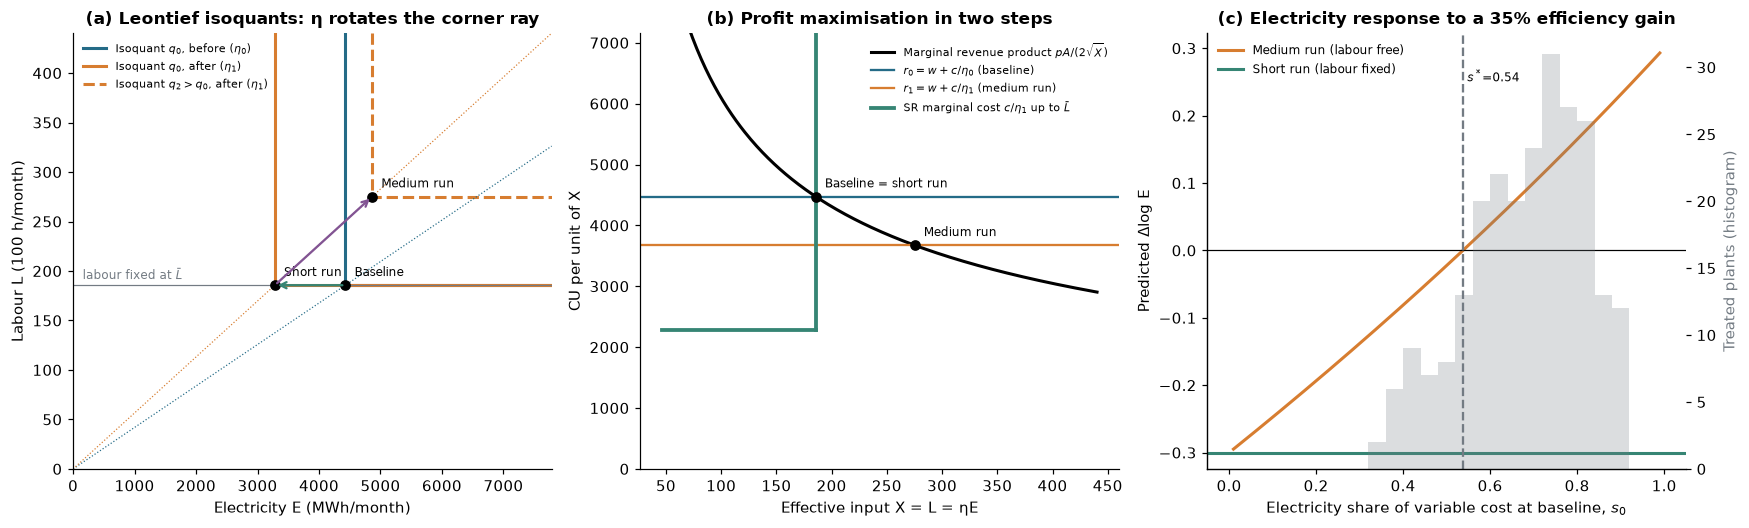

In [9]:
# Diagrams for a representative treated plant (median baseline values), using the estimated 30% log gain
rep = P[P.treated == 1].median(numeric_only=True)
A_r = rep.q0 / np.sqrt(rep.L0)
eta0_r = rep.L0 / rep.E0
G_r = np.exp(0.30)          # efficiency gain estimated in Q5, used here only to draw the diagrams
eta1_r = G_r * eta0_r
r0, r1 = rep.w + rep.c / eta0_r, rep.w + rep.c / eta1_r
X0 = (rep.p * A_r / (2 * r0)) ** 2
X2 = (rep.p * A_r / (2 * r1)) ** 2
Lbar = X0

fig, ax = plt.subplots(1, 3, figsize=(16, 4.9))
# (a) isoquants in (E, L) space
Emax = 1.6 * X2 / eta1_r
def iso(a, X, eta, col, ls, lab):
    a.plot([X / eta, X / eta, Emax], [1.6 * X2, X, X], color=col, ls=ls, lw=2, label=lab)
iso(ax[0], X0, eta0_r, BLUE, "-", "Isoquant $q_0$, before ($\\eta_0$)")
iso(ax[0], X0, eta1_r, ORANGE, "-", "Isoquant $q_0$, after ($\\eta_1$)")
iso(ax[0], X2, eta1_r, ORANGE, "--", "Isoquant $q_2>q_0$, after ($\\eta_1$)")
e = np.linspace(0, Emax, 50)
ax[0].plot(e, eta0_r * e, color=BLUE, lw=.8, ls=":"); ax[0].plot(e, eta1_r * e, color=ORANGE, lw=.8, ls=":")
ax[0].axhline(Lbar, color=GREY, lw=.8)
pts = {"Baseline": (X0 / eta0_r, X0), "Short run": (Lbar / eta1_r, Lbar), "Medium run": (X2 / eta1_r, X2)}
for k, (x, y) in pts.items():
    ax[0].plot(x, y, "ko"); ax[0].annotate(k, (x, y), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax[0].annotate("", xy=pts["Short run"], xytext=pts["Baseline"],
               arrowprops=dict(arrowstyle="->", color=GREEN, lw=1.5))
ax[0].annotate("", xy=pts["Medium run"], xytext=pts["Short run"],
               arrowprops=dict(arrowstyle="->", color=PURPLE, lw=1.5))
ax[0].text(Emax * .02, Lbar * 1.03, "labour fixed at $\\bar L$", fontsize=8, color=GREY)
ax[0].set(xlim=(0, Emax), ylim=(0, 1.6 * X2), xlabel="Electricity E (MWh/month)",
          ylabel="Labour L (100 h/month)", title="(a) Leontief isoquants: η rotates the corner ray")
ax[0].legend(fontsize=7.5, loc="upper left")

# (b) choosing the effective input X: MRP vs its marginal cost
X = np.linspace(X0 * .25, X2 * 1.6, 300)
ax[1].plot(X, rep.p * A_r / (2 * np.sqrt(X)), color="black", lw=2, label="Marginal revenue product $pA/(2\\sqrt{X})$")
ax[1].axhline(r0, color=BLUE, label="$r_0=w+c/\\eta_0$ (baseline)")
ax[1].axhline(r1, color=ORANGE, label="$r_1=w+c/\\eta_1$ (medium run)")
ax[1].plot([X[0], Lbar], [rep.c / eta1_r] * 2, color=GREEN, lw=2.5, label="SR marginal cost $c/\\eta_1$ up to $\\bar L$")
ax[1].plot([Lbar, Lbar], [rep.c / eta1_r, r0 * 1.6], color=GREEN, lw=2.5)
for k, (x, y) in {"Baseline = short run": (X0, r0), "Medium run": (X2, r1)}.items():
    ax[1].plot(x, y, "ko"); ax[1].annotate(k, (x, y), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax[1].set(ylim=(0, r0 * 1.6), xlabel="Effective input X = L = ηE", ylabel="CU per unit of X",
          title="(b) Profit maximisation in two steps")
ax[1].legend(fontsize=7.5)

# (c) the rebound: electricity response vs energy share
s = np.linspace(0.01, .99, 200)
ax[2].plot(s, -2 * np.log(1 - s + s / G_r) - np.log(G_r), color=ORANGE, lw=2, label="Medium run (labour free)")
ax[2].axhline(-np.log(G_r), color=GREEN, lw=2, label="Short run (labour fixed)")
ax[2].axhline(0, color="black", lw=.8)
s_star = np.sqrt(G_r) / (1 + np.sqrt(G_r))
ax[2].axvline(s_star, color=GREY, ls="--"); ax[2].text(s_star + .01, .25, f"$s^*$={s_star:.2f}", fontsize=8)
a2 = ax[2].twinx()
a2.hist(P.loc[P.treated == 1, "energy_share0"], bins=25, range=(0, 1), color=GREY, alpha=.25)
a2.set_ylabel("Treated plants (histogram)", color=GREY); a2.spines["top"].set_visible(False)
ax[2].set(xlabel="Electricity share of variable cost at baseline, $s_0$", ylabel="Predicted Δlog E",
          title=f"(c) Electricity response to a {100*(G_r-1):.0f}% efficiency gain")
ax[2].legend(fontsize=8, loc="upper left")
figure(fig, "04_theory_diagrams")

*Note: the diagrams use an efficiency gain of $G=\eta_1/\eta_0\approx1.35$, which we estimate in Q5. The argument does not depend on its exact value.*

We can make the following observations:
* **(a) Isoquants.** The cheapest bundles lie on the ray $L=\eta E$. Better efficiency rotates the ray: the same output needs less electricity. In the short run labour is stuck at $\bar L$, so the plant moves **left** (green): same labour and output, less electricity. Once labour is free, it moves **out along the new ray** (purple), using more of *both* inputs.
* **(b) How much effective input to buy.** The plant buys until the value of the marginal product equals its cost. At baseline that cost is $r_0$. In the short run it is only the electricity $c/\eta_1$, but the plant cannot go beyond $\bar L$. Once labour is free, the cost is $r_1<r_0$ and the plant expands.
* **(c) Electricity response.** In the short run every plant with the same gain responds the same ($-\log G$). In the medium run the response depends on the electricity share: plants to the right of $s^*$ end up using **more** electricity, and most treated plants are there (grey histogram).

### 4.6 Calculations

In [10]:
# Calculations: is baseline behaviour consistent with profit maximisation?  (uses prices, not only quantities)
P["A"] = P.q0 / np.sqrt(P.L0)                   # from q = A*sqrt(L) at baseline, with L = eta*E
P["eta0"] = P.L0 / P.E0
P["r0"] = P.w + P.c / P.eta0
P["foc_ratio"] = (P.p * P.A / (2 * np.sqrt(P.L0))) / P.r0   # = 1 if p = MC at baseline
foc = P.groupby(P.treated.map(GROUP_LAB)).foc_ratio.describe()[["count", "mean", "std", "min", "max"]]
table_out(foc.round(3), "04_baseline_foc_check")

s_star_G = np.sqrt(G_r) / (1 + np.sqrt(G_r))
calc = pd.Series({
    "Representative treated plant: s0": rep.energy_share0,
    "Assumed efficiency gain G = η1/η0 (from Q5)": G_r,
    "Predicted Δlog E, short run": -np.log(G_r),
    "Predicted Δlog E, medium run": -2 * np.log(1 - rep.energy_share0 + rep.energy_share0 / G_r) - np.log(G_r),
    "Predicted Δlog q, medium run": np.log(r0 / r1),
    "Backfire threshold s*(G)": s_star_G,
    "Share of treated plants with s0 > s*": (P.loc[P.treated == 1, "energy_share0"] > s_star_G).mean(),
}, name="value").to_frame()
table_out(calc.round(3), "04_theory_calculations")

,count,mean,std,min,max
treated,,,,,
Consulting (treated),240.0,1.001,0.012,0.970,1.038
Control,240.0,1.001,0.011,0.964,1.027


,value
Representative treated plant: s0,0.702
Assumed efficiency gain G = η1/η0 (from Q5),1.350
"Predicted Δlog E, short run",-0.300
"Predicted Δlog E, medium run",0.102
"Predicted Δlog q, medium run",0.197
Backfire threshold s*(G),0.537
Share of treated plants with s0 > s*,0.858


We can make the following observations:
* **Plants were maximising profit before the programme.** Using baseline quantities and each plant's prices, the value of the marginal product equals the price of the effective input (ratio 1.00, with about 1% noise). This combines quantities with **prices**, so it is a real check, not something the technology imposes.
* **The model reproduces the effects from Q1–Q3.** For the typical treated plant ($s_0\approx0.70$, $G\approx1.35$) it predicts electricity −26% in the short run and about +11% in the medium run, with output +22%. The estimates are −26% and +9% for electricity (Q3) and +22% for output (Q1).

### 4.7 Assumptions

1. **Technology:** fixed proportions between $L$ and $\eta E$ with square-root returns; $A_i$ does not change with consulting.
2. **Price takers:** plants maximise operating profit at given prices and can sell more without moving the market price (we ignore market equilibrium effects).
3. **Consulting changes $\eta$ once**, in month 1, and the change persists.
4. **Staffing rule:** paid labour is fixed at the baseline level until the review; electricity is always free; no other variable inputs, inventories, entry or exit.
5. **No waste:** $L=\eta E$ whenever both inputs are chosen.

### 4.8 What we should see elsewhere in the data (tested in Q5–Q6)

* Output and labour of treated plants **unchanged** in the short run, while $L/E$ jumps.
* After each review, **output and labour rise**, and electricity rises **in the same month**.
* $L/E$ stays at its new level after the review (the gain persists).
* Larger medium-run increases at plants with a **high electricity share**.
* No change for control plants when their review arrives.

**Assumed vs supported.** Fixed proportions and square-root returns are **assumed**: prices never change, so we cannot test substitution. What the data can support is unchanged output in the short run, the timing of the input changes, the persistence of $L/E$, the pattern by electricity share, and the size of the medium-run expansion.

# 5. Can the initial response reveal the efficiency gain?

**TLDR of Section 5**
* **The short-run fall in electricity measures the efficiency gain**, because output and labour do not move.
* **Consulting raised efficiency by about 35%** (95% CI 34–36%).
* **The gain persists**: it is the same in the medium run, so the later rise in electricity is not the effect wearing off.

### 5.1 Quantities we need and why

With fixed proportions and no waste, $L=\eta E$, so efficiency can be read from two observed quantities:
$$\eta=\frac{L}{E}\ \ \text{(level, labour blocks per MWh)},\qquad \Delta\log\eta=\Delta\log L-\Delta\log E\ \ \text{(change)}.$$
In the short run the fall in electricity alone measures the gain, $\Delta\log\eta=-\Delta\log E$, **only if**:
* labour did not change (the staffing rule binds), and
* output did not change (otherwise part of the fall would be producing less).

### 5.2 Estimate

**Objective:** to check both conditions and estimate the gain, we compare treated with control plants (same regression as in Q3), using averages over the baseline (months −3 to 0) and the short run (months 1–3) to reduce recording noise.

In [11]:
P["eta1"] = P.L1 / P.E1
P["eta2"] = P.L2 / P.E2
P["dlogq_sr"], P["dlogL_sr"] = np.log(P.q1 / P.q0), np.log(P.L1 / P.L0)
P["dlogeta_sr"] = np.log(P.eta1 / P.eta0)
P["dlogeta_mr"] = np.log(P.eta2 / P.eta0)

# Effect of consulting in the short run on each quantity (× 100 ≈ %), plants as units
sr_vars = {"dlogq_sr": "Output", "dlogL_sr": "Labour", "dlogE_sr": "Electricity", "dlogeta_sr": "Efficiency η = L/E"}
m5 = [smf.ols(f"I(100 * {v}) ~ treated + C(stratum)", data=P).fit(cov_type="HC1") for v in sr_vars]
b, se = m5[-1].params["treated"] / 100, m5[-1].bse["treated"] / 100
reg_table([("Δ log, short run (months 1–3) vs baseline, × 100", m5, 1)], columns=list(sr_vars.values()), name="05_short_run",
          below={"Implied % change": [""] * 3 + [f"+{100*np.expm1(b):.1f}% [{100*np.expm1(b - 1.96*se):.1f}, {100*np.expm1(b + 1.96*se):.1f}]"],
                 "Strata FE": ["Yes"] * 4, "Plants (treated / control)": ["240 / 240"] * 4},
          notes="Robust standard errors in parentheses.")

g_eff = diff_ci(P, "dlogeta_sr")      # efficiency gain (log), used in later sections
noise_sd, treat_sd = P.loc[P.treated == 0, "dlogeta_sr"].std(), P.loc[P.treated == 1, "dlogeta_sr"].std()
print(f"Baseline efficiency level: {P.eta0.mean():.3f} labour blocks per MWh (= {100 * P.eta0.mean():.1f} worker-hours per MWh)")
print(f"SD of plant gains: treated {treat_sd:.3f}, control {noise_sd:.3f} (noise) -> SD of true gains ≈ {np.sqrt(treat_sd**2 - noise_sd**2):.3f}")

Baseline efficiency level: 0.042 labour blocks per MWh (= 4.2 worker-hours per MWh)
SD of plant gains: treated 0.066, control 0.019 (noise) -> SD of true gains ≈ 0.063


We can make the following observations:
* **The conditions hold.** Consulting leaves output and labour unchanged in the short run (effects of a fraction of a percent, not significant), while electricity falls by 30 log points (−26%). So the fall is technical.
* **Consulting raised efficiency by about 35%** (30 log points), with a narrow confidence interval.
* **Level vs change.** At baseline, $\eta_0\approx0.042$ labour blocks per MWh: each MWh supports about 4.2 paid worker-hours. Plants differ in this level; the programme's effect is the *change*.
* **Plants differ in their gains.** The spread of gains among treated plants is about three times the noise seen among controls (SD ≈ 0.06 log points). Plant estimates are noisy; the group average is precise.

### 5.3 Does the gain persist?

**Objective:** once labour can adjust, electricity alone no longer measures efficiency, because it mixes the technical and the scale effects. With fixed proportions $\eta=L/E$ still holds, so we compare $L/E$ in the medium run with the short run.

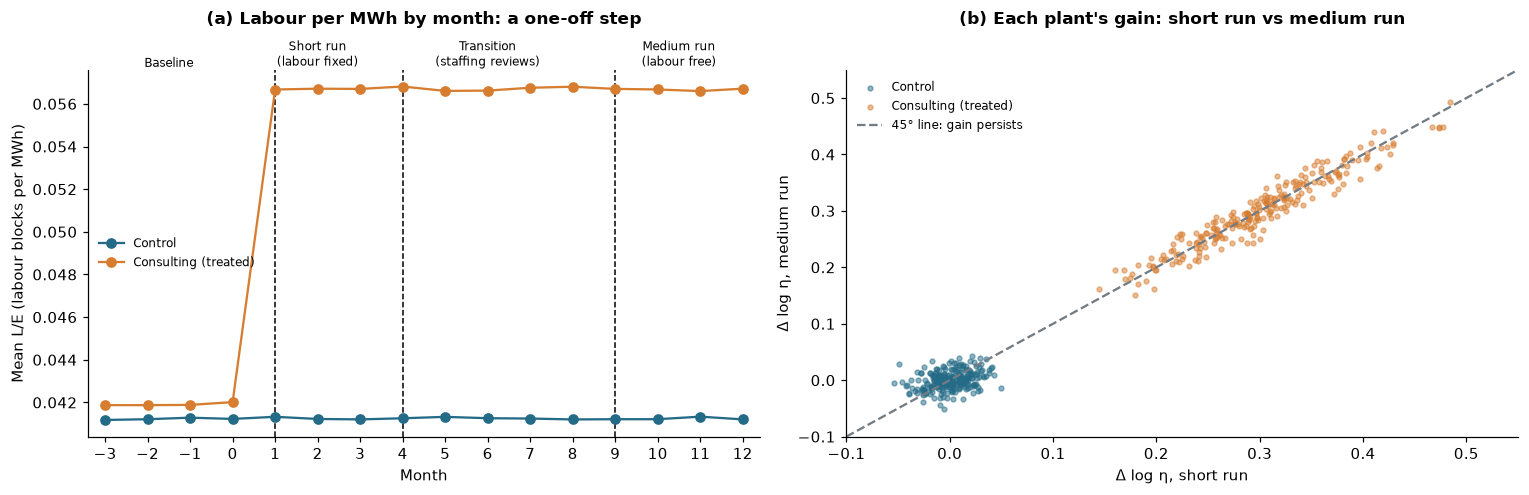

In [12]:
# Persistence: effect of consulting on Δ log(L/E) over different windows (× 100)
P["dlogeta_sr_to_mr"] = np.log(P.eta2 / P.eta1)
pers = {"dlogeta_sr": "Short run vs baseline", "dlogeta_mr": "Medium run vs baseline", "dlogeta_sr_to_mr": "Medium run vs short run"}
m5p = [smf.ols(f"I(100 * {v}) ~ treated + C(stratum)", data=P).fit(cov_type="HC1") for v in pers]
reg_table([("Δ log efficiency η = L/E, × 100", m5p, 1)], columns=list(pers.values()), name="05_persistence",
          below={"Strata FE": ["Yes"] * 3, "Plants (treated / control)": ["240 / 240"] * 3},
          notes="Robust standard errors in parentheses.")

df["eta_ratio"] = df.labor / df.electricity
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
mark_periods(ax[0])
for g in (0, 1):
    ax[0].plot(months, df[df.treated == g].groupby("month").eta_ratio.mean(), "o-", color=GROUP_COL[g], label=GROUP_LAB[g])
ax[0].set_title("(a) Labour per MWh by month: a one-off step", pad=30)
ax[0].set(xlabel="Month", ylabel="Mean L/E (labour blocks per MWh)", xticks=months)
ax[0].legend(fontsize=8, loc="center left")
for g in (0, 1):
    z = P[P.treated == g]
    ax[1].scatter(z.dlogeta_sr, z.dlogeta_mr, s=10, alpha=.5, color=GROUP_COL[g], label=GROUP_LAB[g])
lim = [-.1, .55]
ax[1].plot(lim, lim, color=GREY, ls="--", label="45° line: gain persists")
ax[1].set(xlim=lim, ylim=lim, xlabel="Δ log η, short run", ylabel="Δ log η, medium run")
ax[1].set_title("(b) Each plant's gain: short run vs medium run", pad=30)
ax[1].legend(fontsize=8)
figure(fig, "05_efficiency_gain")

We can make the following observations:
* **The gain persists.** It is the same 30 log points in the short and the medium run, and the change between them is zero (table).
* **Labour per MWh steps up once, in month 1**, and stays flat after the staffing reviews (panel a). Each plant's medium-run gain matches its short-run gain (panel b).
* **So the later rise in electricity is not the effect wearing off**: plants stay more efficient while using more electricity.
* **What depends on the technology.** The short-run estimate only needs output and labour to stay put, which the data confirm. Reading $L/E$ as $\eta$ in the medium run relies on fixed proportions: with substitutable inputs, $L/E$ would also move with scale or prices (Q9).

# 6. Does your explanation predict more than the initial pattern?

**TLDR of Section 6**
* **The model predicts the medium run accurately** from the first three months only: output +22%, labour +49%, electricity +10%.
* **Output grows enough to explain the rebound** in 92% of plants.
* **Plants with a high electricity share rebound most**; Chemicals rebounds more only because electricity weighs more in its costs.
* **Labour and electricity move together, and only in each plant's review month**, as the staffing rule implies.

### 6(a) The magnitude of later choices

* **Hypothesis.** If plants maximise profit with the technology of Q4, their parameters from the first months should predict what they do in the medium run.
* **What we do.** We recover each plant's parameters from the **baseline and the short run only**: $A_i=q_{i0}/\sqrt{L_{i0}}$, $\eta_{i1}=L_{i1}/E_{i1}$ and its prices. Then we predict the medium run (months 9–12) **before** looking at it:
$$X^*=\Big(\frac{pA}{2r_1}\Big)^2,\quad q^*=A\sqrt{X^*},\quad L^*=X^*,\quad E^*=\frac{X^*}{\eta_1},\qquad r_1=w+\frac{c}{\eta_1}.$$

In [13]:
# --- Prediction step: uses only baseline and months 1-3 ---
P["r1"] = P.w + P.c / P.eta1
P["X_pred"] = (P.p * P.A / (2 * P.r1)) ** 2
P["q_pred"] = P.A * np.sqrt(P.X_pred)
P["L_pred"] = P.X_pred
P["E_pred"] = P.X_pred / P.eta1
P["profit_pred"] = P.p * P.q_pred - P.w * P.L_pred - P.c * P.E_pred
P[["q_pred", "L_pred", "E_pred", "profit_pred"]].to_csv("outputs/tables/06a_predictions_made_before_months_9_12.csv")

,Baseline,"Predicted, medium run","Observed, medium run",Predicted change (%),Observed change (%)
Output q (batches/month),80.9,98.7,98.8,21.8,21.8
Labour L (100 h/month),174.6,260.8,260.4,49.0,48.8
Electricity E (MWh/month),4413.7,4870.5,4862.5,10.0,9.9


Controls, predicted vs observed change in electricity (%): 0.2 vs 0.1


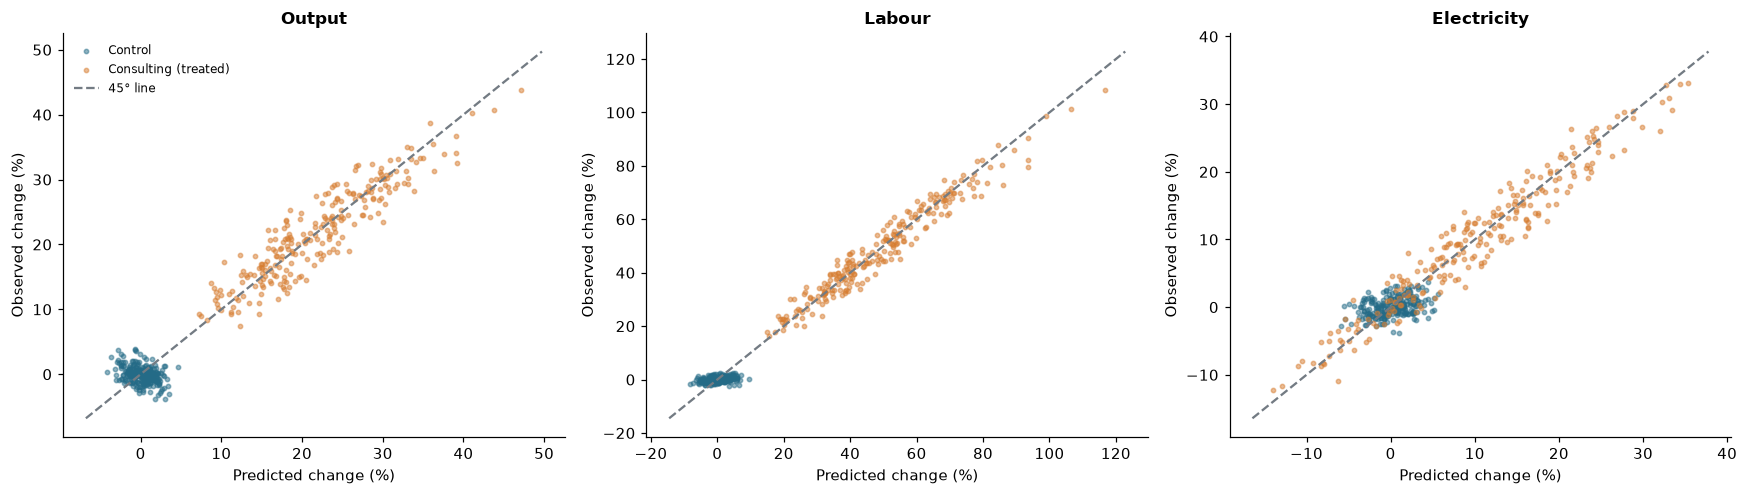

In [14]:
# --- Comparison step: now bring in the held-out months 9-12 ---
P["dlogq_mr"], P["dlogL_mr"] = np.log(P.q2 / P.q0), np.log(P.L2 / P.L0)
P["dlogE_mr_pred"] = np.log(P.E_pred / P.E0)
T = P[P.treated == 1]
fit = pd.DataFrame({lab: {"Baseline": T[x0].mean(), "Predicted, medium run": T[pr].mean(), "Observed, medium run": T[x2].mean(),
                          "Predicted change (%)": 100 * (T[pr] / T[x0] - 1).mean(), "Observed change (%)": 100 * (T[x2] / T[x0] - 1).mean()}
                    for lab, x0, pr, x2 in [("Output q (batches/month)", "q0", "q_pred", "q2"),
                                            ("Labour L (100 h/month)", "L0", "L_pred", "L2"),
                                            ("Electricity E (MWh/month)", "E0", "E_pred", "E2")]}).T
table_out(fit.round(1), "06a_prediction_fit")
Ct = P[P.treated == 0]
print("Controls, predicted vs observed change in electricity (%):",
      round(100 * (Ct.E_pred / Ct.E0 - 1).mean(), 1), "vs", round(100 * (Ct.E2 / Ct.E0 - 1).mean(), 1))

# Plant by plant: predicted vs observed % change, medium run vs baseline
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, (lab, x0, pr, x2) in zip(ax, [("Output", "q0", "q_pred", "q2"), ("Labour", "L0", "L_pred", "L2"),
                                     ("Electricity", "E0", "E_pred", "E2")]):
    for g in (0, 1):
        z = P[P.treated == g]
        a.scatter(100 * (z[pr] / z[x0] - 1), 100 * (z[x2] / z[x0] - 1), s=8, alpha=.5, color=GROUP_COL[g], label=GROUP_LAB[g])
    lim = a.get_xlim()
    a.plot(lim, lim, color=GREY, ls="--", label="45° line")
    a.set(title=lab, xlabel="Predicted change (%)", ylabel="Observed change (%)")
ax[0].legend(fontsize=8)
figure(fig, "06a_out_of_sample")

In [15]:
# Discrepancies: are prediction errors related to plant characteristics? (treated plants)
T = P[P.treated == 1].assign(s0c=lambda z: z.energy_share0 - .5, chem=lambda z: (z.sector == "Chemicals").astype(int))
for v, x2, pr in [("q", "q2", "q_pred"), ("L", "L2", "L_pred"), ("E", "E2", "E_pred")]:
    T["err_" + v] = 100 * np.log(T[x2] / T[pr])
m6a = [smf.ols(f"err_{v} ~ chem + C(adjust_month) + s0c", data=T).fit(cov_type="HC1") for v in "qLE"]
reg_table([(None, m6a, 2)], columns=["Output", "Labour", "Electricity"], name="06a_discrepancies",
          coef={"chem": "Chemicals", "C(adjust_month)[T.6]": "Review in month 6", "C(adjust_month)[T.8]": "Review in month 8",
                "s0c": "Electricity share s0 (− 0.5)", "Intercept": "Constant"},
          below={"Plants": ["240"] * 3},
          notes="Treated plants. Outcome: prediction error, 100 × log(observed / predicted), medium run. Robust standard errors in parentheses.")

,(1)Output,(2)Labour,(3)Electricity
Chemicals,0.00,0.01,-0.05
,(0.32),(0.37),(0.31)
Review in month 6,-0.04,0.27,-0.02
,(0.39),(0.45),(0.35)
Review in month 8,-0.23,0.02,-0.23
,(0.36),(0.41),(0.34)
Electricity share s0 (− 0.5),-0.86,-1.67,-1.36
,(1.17),(1.36),(1.08)
Constant,0.26,0.11,0.28
,(0.33),(0.37),(0.29)


* **Result.** The model predicts that treated plants raise output by about 22%, labour by about 49% and electricity by about 10% in the medium run, and this is what we observe, also plant by plant (figure). Control plants are predicted not to change, and they do not.
* **Discrepancies.** Prediction errors are not related to sector, review month or electricity share (no coefficient is significant, and the average error is close to zero). What remains is consistent with recording noise.
* **Reading.** Nothing from months 4–12 entered the parameters, so this is a genuine out-of-sample test of the whole model.

### 6(b) Production and electricity

* **Hypothesis.** With fixed proportions, $q=A\sqrt{\eta E}$, so from baseline to the medium run
$$\Delta\log E=2\,\Delta\log q-\Delta\log\eta .$$
Electricity rises above baseline **only if output grows by more than half the efficiency gain**, $\Delta\log q_{MR}>\tfrac12\Delta\log\eta_{SR}$. A positive output response is not enough.

,Treated plants,Meet criterion,Electricity above baseline,Classifications agree (%)
sector,,,,
All,240,199,200,92.0
Chemicals,120,107,107,92.0
Textiles,120,92,93,92.0


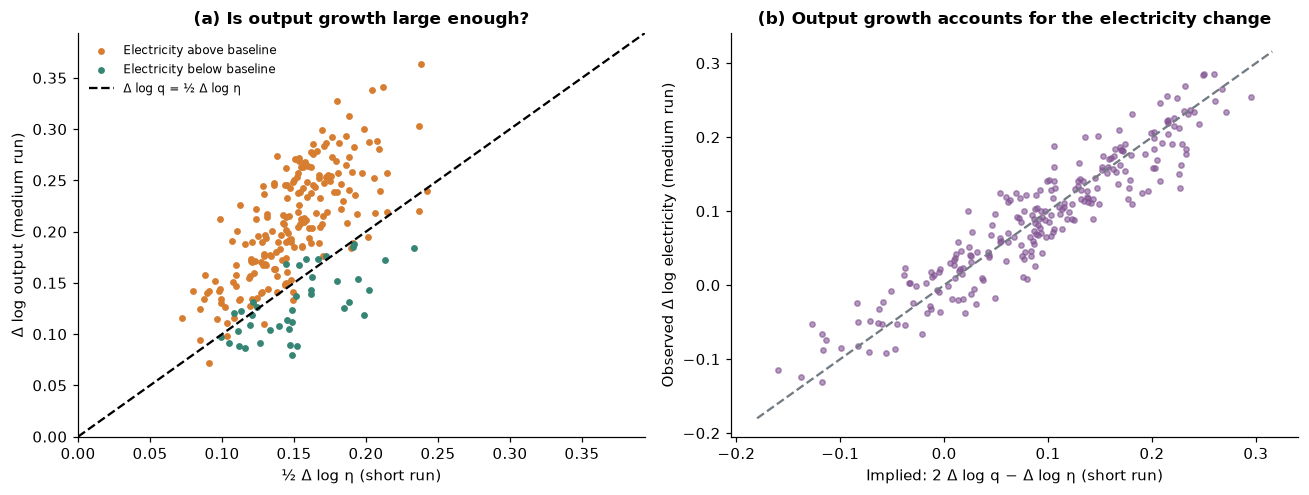

In [16]:
P["half_gain"] = .5 * P.dlogeta_sr
P["dlogE_from_q"] = 2 * P.dlogq_mr - P.dlogeta_sr
T = P[P.treated == 1].assign(meets=lambda z: z.dlogq_mr > z.half_gain, above=lambda z: z.dlogE_mr > 0)
crit = (pd.concat([T, T.assign(sector="All")]).assign(agree=lambda z: 100 * (z.meets == z.above))
        .groupby("sector").agg(plants=("meets", "size"), meets=("meets", "sum"), above=("above", "sum"), agree=("agree", "mean")))
crit.columns = ["Treated plants", "Meet criterion", "Electricity above baseline", "Classifications agree (%)"]
table_out(crit.round(0), "06b_criterion")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].scatter(T.half_gain[T.above], T.dlogq_mr[T.above], s=12, color=ORANGE, label="Electricity above baseline")
ax[0].scatter(T.half_gain[~T.above], T.dlogq_mr[~T.above], s=12, color=GREEN, label="Electricity below baseline")
lim = [0, T[["half_gain", "dlogq_mr"]].max().max() + .03]
ax[0].plot(lim, lim, color="black", ls="--", label="Δ log q = ½ Δ log η")
ax[0].set(xlim=lim, ylim=lim, xlabel="½ Δ log η (short run)", ylabel="Δ log output (medium run)",
          title="(a) Is output growth large enough?")
ax[0].legend(fontsize=8)
ax[1].scatter(T.dlogE_from_q, T.dlogE_mr, s=12, color=PURPLE, alpha=.6)
lim = [T[["dlogE_from_q", "dlogE_mr"]].min().min() - .02, T[["dlogE_from_q", "dlogE_mr"]].max().max() + .02]
ax[1].plot(lim, lim, color=GREY, ls="--")
ax[1].set(xlabel="Implied: 2 Δ log q − Δ log η (short run)", ylabel="Observed Δ log electricity (medium run)",
          title="(b) Output growth accounts for the electricity change")
figure(fig, "06b_output_vs_electricity")

* **Result.** 199 of 240 treated plants meet the criterion and 200 use more electricity than at baseline. The two agree for 92% of plants, and the few mismatches lie close to the line, where recording noise decides (panel a). The size also matches: the electricity change implied by output growth equals the observed change plant by plant (panel b).
* **Reading.** If $\eta$ were measured in the medium run itself, the relation would be an accounting identity and prove nothing. Using $\eta$ from the short run makes it a test: it holds only if the gain persisted and $A$ did not change. 6(a) is the stronger test, because it uses no medium-run quantities at all.

### 6(c) Differences across firms

* **Hypothesis.** From Q4, $\Delta\log E_{MR}=-2\log(1-s_0+s_0/G)-\log G$. Two characteristics matter: the **size of the gain** $\Delta\log\eta$ (Q5), and the **response to a given gain**, driven by the baseline electricity share $s_0$. Plants with a high $s_0$ should rebound most, and sector should matter only through $s_0$.

,Mean s0,Efficiency gain (%),Observed Δ electricity (%),Predicted Δ electricity (%),Plants above baseline (%)
share_bin,,,,,
Q1 (lowest s0),0.50,35.57,-2.34,-2.38,33.33
Q2,0.65,35.55,6.66,6.51,100.00
Q3,0.75,33.83,13.67,13.87,100.00
Q4 (highest s0),0.84,36.22,21.62,22.09,100.00


,(1)Sector,(2)Electricity share,(3)Share × gain,(4)Sector + share
Chemicals,3.90***,,,-0.39
,(1.13),,,(0.35)
Electricity share s0 (− 0.5),,63.68***,62.66***,64.04***
,,(1.41),(0.89),(1.43)
Efficiency gain Δ log η (− mean),,,-16.69***,
,,,(2.12),
s0 × Δ log η,,,197.81***,
,,,(12.68),
Plants,240,240,240,240
R²,0.05,0.91,0.96,0.91


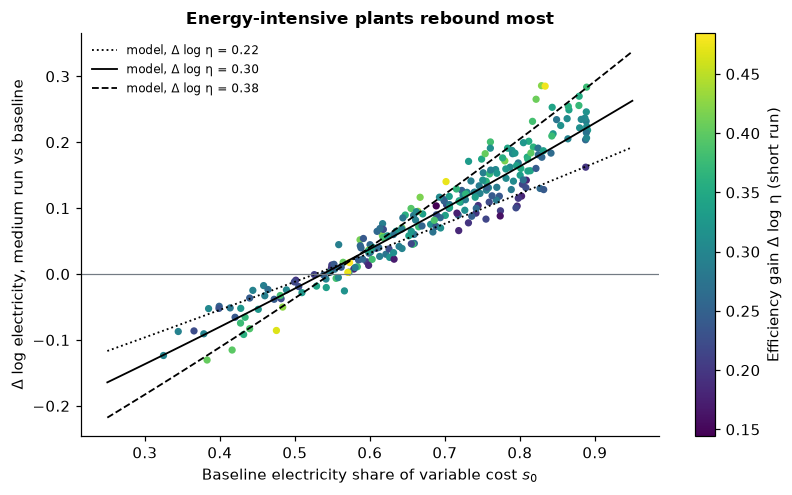

In [17]:
# Which baseline characteristics predict the medium-run electricity response? (treated plants only)
T = P[P.treated == 1].copy()
T["g"] = T.dlogeta_sr                                    # efficiency gain Δ log η from the short run
T["y"] = 100 * T.dlogE_mr                                # Δ log electricity × 100, medium run vs baseline
T["chem"] = (T.sector == "Chemicals").astype(int)
T["s0c"], T["gc"] = T.energy_share0 - .5, T.g - T.g.mean()   # centred, so main effects are read at s0 = 0.5 and mean g
T["share_bin"] = pd.qcut(T.energy_share0, 4, labels=["Q1 (lowest s0)", "Q2", "Q3", "Q4 (highest s0)"])

qt = T.groupby("share_bin", observed=True).agg(
    s0=("energy_share0", "mean"), gain=("g", lambda x: 100 * np.expm1(x).mean()),
    observed=("dlogE_mr", lambda x: 100 * np.expm1(x).mean()), predicted=("dlogE_mr_pred", lambda x: 100 * np.expm1(x).mean()),
    above=("dlogE_mr", lambda x: 100 * (x > 0).mean()))
qt.columns = ["Mean s0", "Efficiency gain (%)", "Observed Δ electricity (%)", "Predicted Δ electricity (%)",
              "Plants above baseline (%)"]
table_out(qt.round(2), "06c_by_energy_share")

m6c = [smf.ols(fml, data=T).fit(cov_type="HC1")
       for fml in ["y ~ chem", "y ~ s0c", "y ~ s0c * gc", "y ~ chem + s0c"]]
reg_table([(None, m6c, 2)], columns=["Sector", "Electricity share", "Share × gain", "Sector + share"], name="06c_regression",
          coef={"chem": "Chemicals", "s0c": "Electricity share s0 (− 0.5)", "gc": "Efficiency gain Δ log η (− mean)",
                "s0c:gc": "s0 × Δ log η"},
          below={"Plants": [f"{int(m.nobs)}" for m in m6c], "R²": [f"{m.rsquared:.2f}" for m in m6c]},
          notes="Treated plants. Outcome: Δ log electricity × 100, medium run (months 9–12) vs baseline. Robust standard errors in parentheses.")
fig, ax = plt.subplots(figsize=(7.5, 4.6))
sc = ax.scatter(T.energy_share0, T.dlogE_mr, c=T.g, cmap="viridis", s=14)
plt.colorbar(sc, ax=ax, label="Efficiency gain Δ log η (short run)")
s = np.linspace(.25, .95, 100)
for gq, ls in zip(T.g.quantile([.1, .5, .9]), [":", "-", "--"]):
    G = np.exp(gq)
    ax.plot(s, -2 * np.log(1 - s + s / G) - np.log(G), color="black", ls=ls, lw=1.2, label=f"model, Δ log η = {gq:.2f}")
ax.axhline(0, color=GREY, lw=.8)
ax.set(xlabel="Baseline electricity share of variable cost $s_0$", ylabel="Δ log electricity, medium run vs baseline",
       title="Energy-intensive plants rebound most")
ax.legend(fontsize=8)
figure(fig, "06c_heterogeneity")

* **Result.** Across quartiles of $s_0$, the medium-run change rises from about −2% to about +22%, matching the model in each quartile. The efficiency gain is about the same (≈ 35%) in every quartile. In the regression, Chemicals plants rebound more (column 1), but the difference disappears once we control for $s_0$ (column 4).
* **Reading.** The electricity share, not the size of the gain, decides who rebounds most. Chemicals plants rebound more because electricity weighs more in their costs, not because consulting worked differently there.

### 6(d) Input relationships and timing

* **Hypothesis.** With fixed proportions and a constant $\eta$ after month 1:
  * from the short to the medium run, $\Delta\log E=\Delta\log L$ (slope 1, constant 0);
  * from baseline to the medium run, $\Delta\log E=\Delta\log L-\Delta\log\eta$ (1 on labour, −1 on the gain);
  * labour, output and electricity should jump **in each plant's review month** and not before; controls should not react.

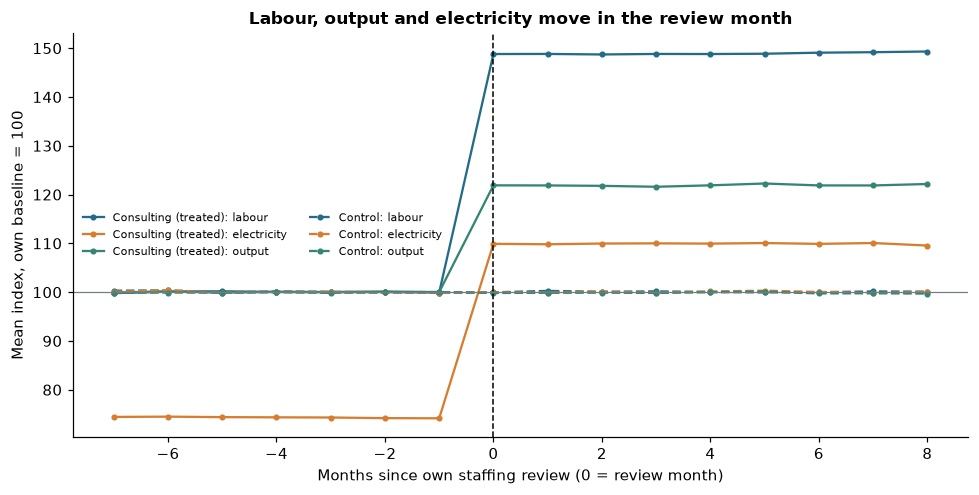

In [18]:
# Input relationships implied by fixed proportions (treated plants), and timing relative to the staffing review
P["dlogL_srmr"] = np.log(P.L2 / P.L1)
P["dlogE_srmr"] = np.log(P.E2 / P.E1)
T = P[P.treated == 1]
m6d = [smf.ols("dlogE_srmr ~ dlogL_srmr", data=T).fit(cov_type="HC1"),
       smf.ols("dlogE_mr ~ dlogL_mr", data=T).fit(cov_type="HC1"),
       smf.ols("dlogE_mr ~ dlogL_mr + dlogeta_sr", data=T).fit(cov_type="HC1")]
for m, x in zip(m6d, ["dlogL_srmr", "dlogL_mr", "dlogL_mr"]):
    m.params, m.bse, m.pvalues = (s.rename({x: "dlogL"}) for s in (m.params, m.bse, m.pvalues))
reg_table([(None, m6d, 2)], columns=["Short → medium run", "Baseline → medium run", "Baseline → medium run"],
          name="06d_input_relationships",
          coef={"dlogL": "Δ log labour", "dlogeta_sr": "Efficiency gain Δ log η (short run)", "Intercept": "Constant"},
          below={"Model predicts": ["slope 1, constant 0", "—", "1 on labour, −1 on gain"], "Plants": ["240"] * 3},
          notes="Treated plants. Outcome: Δ log electricity over the same window as labour. Robust standard errors in parentheses.")

# Timing: align plants by their own review month
df["event"] = df.month - df.adjust_month
ev = (100 * df[df.month >= 1].assign(iq=df.output / df.q0, iL=df.labor / df.L0, iE=df.electricity / df.E0)
       .groupby(["treated", "event"])[["iq", "iL", "iE"]].mean())
fig, ax = plt.subplots(figsize=(9, 4.6))
for g, ls in [(1, "-"), (0, "--")]:
    z = ev.loc[g]
    ax.plot(z.index, z.iL, ls, marker="o", ms=3, color=BLUE, label=f"{GROUP_LAB[g]}: labour")
    ax.plot(z.index, z.iE, ls, marker="o", ms=3, color=ORANGE, label=f"{GROUP_LAB[g]}: electricity")
    ax.plot(z.index, z.iq, ls, marker="o", ms=3, color=GREEN, label=f"{GROUP_LAB[g]}: output")
ax.axvline(0, color="black", ls="--", lw=1)
ax.axhline(100, color=GREY, lw=.8)
ax.set(xlabel="Months since own staffing review (0 = review month)", ylabel="Mean index, own baseline = 100",
       title="Labour, output and electricity move in the review month")
ax.legend(fontsize=7, ncol=2, loc="center left")
figure(fig, "06d_inputs_timing")

* **Result.** From the short to the medium run, electricity and labour move one-for-one (column 1). From baseline, the raw slope is well below 1 (column 2), because plants with larger gains both expand more and save more electricity per worker. Controlling for each plant's gain gives 0.97 and −0.91 (column 3), close to 1 and −1; the gain is estimated with noise from three months, which pulls its coefficient towards zero. In the timing figure, treated plants are flat until their review, jump in that month and stay flat; controls do not react.
* **Reading.** The comparison window matters: from the short run we see only the scale change; from baseline we see the scale change and the one-off technical change together. Because the jump comes at different calendar months for different groups, explanations tied to calendar time (seasonality, learning, gradual decay) are ruled out.

### 6.5 What each piece of evidence establishes

| Evidence | Type | What it establishes |
|---|---|---|
| Short run: $q, L$ unchanged, $E$ falls (Q5) | Test | The fall is technical, not producing less |
| $L/E$ constant after month 1 (Q5) | Test, given fixed proportions | The efficiency gain persists |
| Medium run predicted from months −3 to 3 (6a) | **Out-of-sample prediction** | Profit maximisation explains the size of the expansion |
| Output growth vs electricity (6b) | Test across windows (identity within one window) | Output growth is large enough to explain the rebound |
| Rebound rises with $s_0$; sector only through $s_0$ (6c) | Test across plants | The mechanism runs through the cost of energy services |
| Slopes 1 and −1 (6d) | Largely implied by fixed proportions | Inputs move together |
| Jumps only in the review month (6d) | Timing test | The staffing rule is the binding constraint |

### 6.6 Alternative explanations

* **The advice fades.** Electricity would rise with unchanged output and labour, $L/E$ would fall back, and the rise would be gradual. We see the opposite on all three counts.
* **Consulting also raised productivity $A$.** Output would have risen already in the short run, when labour was fixed. It did not, and the prediction with baseline $A$ fits the medium run.
* **Demand shocks.** Ruled out by random assignment, constant prices and flat controls.

### 6.7 Limits of the evidence

Prices never change, so we cannot test substitution between labour and electricity: fixed proportions is assumed. The data cover 12 months and leave out capital, entry, exit and market-price effects. Consulting costs and environmental damages are not observed.

# 7. Evaluate a further efficiency improvement

**TLDR of Section 7**
* **With labour fixed**, a further 20% gain cuts electricity by 16.7%.
* **With labour free**, plants expand and total electricity *rises* by about 4%.
* **Scaling the original effect overstates the rebound** (+5.6% vs +3.8% from the model), because the electricity share has already fallen.

### 7.1 Scenarios

A follow-up programme raises each treated plant's current efficiency by a further 20%, $\eta_{FU}=1.2\,\eta_1$, with $A_i$ and prices unchanged. We compare two scenarios with the **same no-follow-up baseline**: each plant's medium-run choice at its current efficiency $\eta_1$, from the model of Q6(a), with $X_1=(pA/2r_1)^2$.

| Scenario | Labour | Electricity | Output |
|---|---|---|---|
| Labour fixed at the current medium-run level | $X_1$ | $X_1/\eta_{FU}$ | unchanged |
| Labour free | $X_{FU}=(pA/2r_{FU})^2$, with $r_{FU}=w+c/\eta_{FU}$ | $X_{FU}/\eta_{FU}$ | $A\sqrt{X_{FU}}$ |

Operating profit is $pq-wL-cE$; it **excludes** the unknown cost of delivering consulting.

### 7.2 Results

,No follow-up (total per month),Labour fixed: change (%),Labour free: change (%)
Output q (thousand batches),23.7,0.0,11.8
Labour L (thousand blocks of 100 h),62.6,0.0,25.2
Electricity E (GWh),1168.9,-16.7,4.4
Operating profit (million CU),279.9,11.5,13.0


,"Electricity, labour fixed (%)","Electricity, labour free (%)","Output, labour free (%)",Plants whose electricity rises,Plants
sector,,,,,
All,-16.7,3.8,11.6,181,240
Chemicals,-16.7,5.2,12.3,100,120
Textiles,-16.7,2.5,10.8,81,120


Original programme: efficiency +35% -> electricity +9.4% in the medium run.
Follow-up (+20%): naive proportional extrapolation +5.6%; model +3.8% (mean plant). Mean electricity share: s0 = 0.68 before the programme, s1 = 0.62 now.


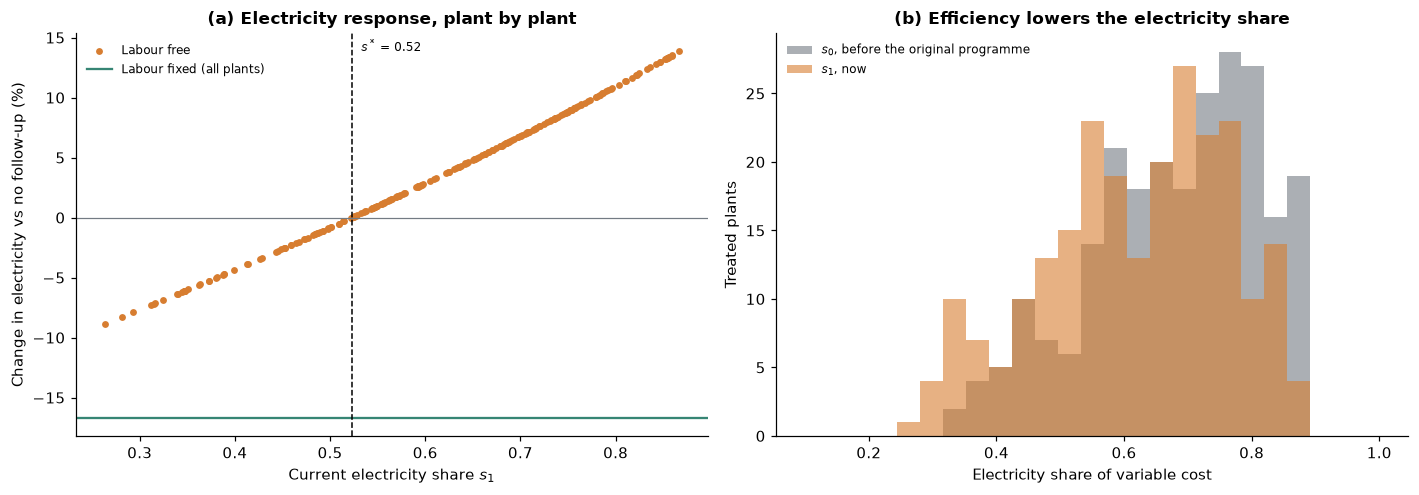

In [19]:
T = P[P.treated == 1].copy()
T["eta_fu"] = 1.2 * T.eta1

def outcome(Tdf, X, eta):
    q, L, E = Tdf.A * np.sqrt(X), X, X / eta
    return pd.DataFrame({"q": q, "L": L, "E": E, "profit": Tdf.p * q - Tdf.w * L - Tdf.c * E})

X_base = (T.p * T.A / (2 * (T.w + T.c / T.eta1))) ** 2
X_free = (T.p * T.A / (2 * (T.w + T.c / T.eta_fu))) ** 2
sc_base, sc_fix, sc_free = outcome(T, X_base, T.eta1), outcome(T, X_base, T.eta_fu), outcome(T, X_free, T.eta_fu)

# Aggregate: totals for the 240 treated plants, and % change vs no follow-up
tot = pd.DataFrame({"No follow-up (total per month)": sc_base.sum(), "fix": sc_fix.sum(), "free": sc_free.sum()})
agg = pd.DataFrame({"No follow-up (total per month)": tot.iloc[:, 0] / [1e3, 1e3, 1e3, 1e6],
                    "Labour fixed: change (%)": 100 * (tot.fix / tot.iloc[:, 0] - 1),
                    "Labour free: change (%)": 100 * (tot.free / tot.iloc[:, 0] - 1)})
agg.index = ["Output q (thousand batches)", "Labour L (thousand blocks of 100 h)", "Electricity E (GWh)", "Operating profit (million CU)"]
table_out(agg.round(1), "07_follow_up_aggregate")

# Differences across plants, by sector (mean % change per plant vs no follow-up)
plant = pd.DataFrame({"E_fix": 100 * (sc_fix.E / sc_base.E - 1), "E_free": 100 * (sc_free.E / sc_base.E - 1),
                      "q_free": 100 * (sc_free.q / sc_base.q - 1), "E_up": sc_free.E > sc_base.E,
                      "s1": T.c / T.eta1 / (T.w + T.c / T.eta1), "s0": T.energy_share0, "sector": T.sector})
by_sec = pd.concat([plant, plant.assign(sector="All")]).groupby("sector").agg(
    E_fix=("E_fix", "mean"), E_free=("E_free", "mean"), q_free=("q_free", "mean"), E_up=("E_up", "sum"), plants=("E_up", "size"))
by_sec.columns = ["Electricity, labour fixed (%)", "Electricity, labour free (%)", "Output, labour free (%)",
                  "Plants whose electricity rises", "Plants"]
table_out(by_sec.round(1), "07_follow_up_by_sector")

# Naive extrapolation of the original medium-run effect vs the model
orig_mr, gain0 = diff_ci(P, "dlogE_mr").effect, g_eff.effect
print(f"Original programme: efficiency +{100*np.expm1(gain0):.0f}% -> electricity +{100*np.expm1(orig_mr):.1f}% in the medium run.")
print(f"Follow-up (+20%): naive proportional extrapolation +{100*np.expm1(orig_mr*np.log(1.2)/gain0):.1f}%; "
      f"model +{100*np.expm1(np.log(sc_free.E / sc_base.E)).mean():.1f}% (mean plant). "
      f"Mean electricity share: s0 = {plant.s0.mean():.2f} before the programme, s1 = {plant.s1.mean():.2f} now.")

s_star = np.sqrt(1.2) / (1 + np.sqrt(1.2))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].scatter(plant.s1, plant.E_free, s=12, color=ORANGE, label="Labour free")
ax[0].axhline(100 * (1 / 1.2 - 1), color=GREEN, label="Labour fixed (all plants)")
ax[0].axhline(0, color=GREY, lw=.8)
ax[0].axvline(s_star, color="black", ls="--", lw=1)
ax[0].text(s_star + .01, ax[0].get_ylim()[1] * .9, f"$s^*$ = {s_star:.2f}", fontsize=8)
ax[0].set(xlabel="Current electricity share $s_1$", ylabel="Change in electricity vs no follow-up (%)",
          title="(a) Electricity response, plant by plant")
ax[0].legend(fontsize=8)
ax[1].hist(plant.s0, bins=25, range=(0.1, 1), color=GREY, alpha=.6, label="$s_0$, before the original programme")
ax[1].hist(plant.s1, bins=25, range=(0.1, 1), color=ORANGE, alpha=.6, label="$s_1$, now")
ax[1].set(xlabel="Electricity share of variable cost", ylabel="Treated plants", title="(b) Efficiency lowers the electricity share")
ax[1].legend(fontsize=8)
figure(fig, "07_follow_up")

We can make the following observations (240 treated plants, against no follow-up):
* **Labour fixed:** output and labour do not change, and every plant's electricity falls by 16.7% ($1/1.2-1$). Profit rises by the electricity bill saved. This is the short-run logic of Q4 again.
* **Labour free:** plants expand output (+12%) and labour (+25%), and total electricity **rises by about 4%** instead of falling. Profit rises more than with labour fixed, because the plant can re-optimise.
* **Differences across plants:** with labour free, 181 of 240 plants increase electricity, namely those with a high current electricity share $s_1$, above $s^*\approx0.52$ for a 20% gain (panel a). The rise is larger in Chemicals than in Textiles.
* **Why scaling the original effect is misleading:** the original programme raised efficiency by 35% and medium-run electricity by 9.4%. Scaling that to a 20% gain gives about +5.6%; the model gives about +3.8%. The rebound depends on the electricity share, and **the share falls as efficiency rises**: the first programme already lowered it from 0.68 to 0.62 (panel b), so a further gain triggers a smaller expansion. The response also changes sign with the horizon (labour fixed or free).

### 7.3 Optional extension: a plant-specific electricity levy

**Objective:** to find the per-MWh levy $t_i$ that keeps each plant's medium-run electricity at or below its baseline $E_{i0}$, after the original programme. With the levy, the price of the effective input is $r=w+(c+t)/\eta_1$. Setting $E^*=E_{i0}$:
$$t_i=\max\Big\{0,\ \eta_{i1}\Big(\frac{p_iA_i}{2\sqrt{\eta_{i1}E_{i0}}}-w_i\Big)-c_i\Big\}.$$

In [20]:
T = P[P.treated == 1].copy()
t = (T.eta1 * (T.p * T.A / (2 * np.sqrt(T.eta1 * T.E0)) - T.w) - T.c).clip(lower=0)
X_tax = (T.p * T.A / (2 * (T.w + (T.c + t) / T.eta1))) ** 2
q_tax, E_tax = T.A * np.sqrt(X_tax), X_tax / T.eta1
profit_tax = T.p * q_tax - T.w * X_tax - (T.c + t) * E_tax
lev = pd.DataFrame({
    "Baseline (before the programme)": [T.q0.sum() / 1e3, T.E0.sum() / 1e3, T.profit0.sum() / 1e6, 0],
    "Medium run, no levy": [sc_base.q.sum() / 1e3, sc_base.E.sum() / 1e3, sc_base.profit.sum() / 1e6, 0],
    "Medium run, with levy": [q_tax.sum() / 1e3, E_tax.sum() / 1e3, profit_tax.sum() / 1e6, (t * E_tax).sum() / 1e6]},
    index=["Output q (thousand batches)", "Electricity E (GWh)", "Operating profit after levy (million CU)", "Levy revenue (million CU)"])
table_out(lev.round(1), "07_levy")
print(f"Plants needing a levy: {(t > 0).sum()} of 240; median levy among them {t[t > 0].median():.1f} CU/MWh "
      f"({(100 * t / T.c)[t > 0].median():.1f}% of their electricity price).")

,Baseline (before the programme),"Medium run, no levy","Medium run, with levy"
Output q (thousand batches),19.4,23.7,22.5
Electricity E (GWh),1059.3,1168.9,1050.7
Operating profit after levy (million CU),225.2,279.9,261.2
Levy revenue (million CU),0.0,0.0,17.1


Plants needing a levy: 202 of 240; median levy among them 12.8 CU/MWh (8.7% of their electricity price).


We can make the following observations:
* **202 of 240 treated plants need a levy**, typically about 9% of their electricity price; the rest already use less electricity than at baseline.
* **With the levy, total electricity returns to its baseline level while output stays above baseline**, because plants are now more efficient.
* **Profit plus levy revenue is still well above baseline profit**: the efficiency gain is a real saving, now shared between plants and the government.

**Why this is not an optimal environmental tax, nor a feasible uniform policy.**
* A corrective tax should equal the **marginal external damage** of electricity use. This levy instead hits an arbitrary target (baseline electricity), and damages are not observed.
* It is **plant-specific**: setting it requires knowing each plant's $A_i$, $\eta_i$ and prices. A single levy for all plants would be too high for some and too low for others.
* Levy revenue is a transfer, not a gain in welfare.

# 8. Brief the policymaker

##### Recommendation: do not scale up consulting on its own if the goal is lower electricity use

**What happened.** In a randomised pilot with 480 plants, consulting made treated plants about **35% more electricity-efficient** (95% CI 34–36%), and the gain lasted the whole year. Electricity use fell by about **26%** in the first three months. But by months 9–12 treated plants used about **9% more** electricity than comparable plants without consulting (95% CI 8–11%). The first-year saving (about 600 GWh) would be used up roughly six months later.

**Why.** Efficiency makes each unit of output cheaper to produce. While staffing levels were locked in, plants could only use the gain to buy less electricity. Once their staffing reviews allowed it, they hired more workers and produced about 22% more, which needed more electricity. Where electricity is a large share of costs, as in most chemicals plants, this expansion more than offsets the saving. A simple production model calibrated on the first three months predicted these later choices accurately.

**Output, profits and welfare.** Treated plants produce more and earn higher operating profits. Whether society gains depends on the environmental cost of the extra electricity and on what consulting costs, neither of which we observe.

**The follow-up.** A further 20% efficiency gain would cut electricity by about 17% while staffing is fixed, but once plants adjust staffing, total electricity would *rise* by about 4%, mostly at energy-intensive plants.

**Recommendation and next step.** If the goal is lower electricity use, consulting alone is not enough. It should be paired with an electricity price signal (for example, a levy related to environmental damage) or targeted at plants where electricity is a small share of costs. Most useful next: estimates of environmental damage per MWh, programme costs, and a test with varying electricity prices to see how easily plants substitute labour for electricity.

### Reproducibility
All figures and tables are saved in `outputs/`. The cell below lists them and confirms the notebook ran from top to bottom.

In [21]:
for d in ["outputs/figures", "outputs/tables"]:
    print(d, "→", len(os.listdir(d)), "files:", ", ".join(sorted(os.listdir(d))))

outputs/figures → 10 files: 01_electricity_by_month.png, 01_inputs_output_by_month.png, 02_time_pattern.png, 04_theory_diagrams.png, 05_efficiency_gain.png, 06a_out_of_sample.png, 06b_output_vs_electricity.png, 06c_heterogeneity.png, 06d_inputs_timing.png, 07_follow_up.png
outputs/tables → 20 files: .gitkeep, 01_baseline_balance.csv, 01_design.csv, 01_panel_checks.csv, 02_phases.csv, 03_effects.csv, 04_baseline_foc_check.csv, 04_theory_calculations.csv, 05_persistence.csv, 05_short_run.csv, 06a_discrepancies.csv, 06a_prediction_fit.csv, 06a_predictions_made_before_months_9_12.csv, 06b_criterion.csv, 06c_by_energy_share.csv, 06c_regression.csv, 06d_input_relationships.csv, 07_follow_up_aggregate.csv, 07_follow_up_by_sector.csv, 07_levy.csv


# 9. Optional: a short Cobb–Douglas comparison

**TLDR of Section 9**
* **With Cobb–Douglas, labour and electricity can replace each other.** Better efficiency makes each MWh more useful, so plants buy *more* electricity, even with labour fixed.
* **The data reject it on every prediction**, most clearly because electricity fell in the short run while output did not move.
* **Rejecting it does not prove our model is the only right one.**

### 9.1 The alternative technology

$$q=A_i\,L^{1/4}(\eta E)^{1/4}$$
Same returns to scale as before (doubling both inputs raises output by $\sqrt2$), but now the inputs can substitute for each other.

### 9.2 Both inputs free: the labour-to-electricity ratio

The first-order conditions are $\dfrac{pq}{4L}=w$ and $\dfrac{pq}{4E}=c$, so
$$wL=cE\quad\Rightarrow\quad\frac{L}{E}=\frac{c}{w}.$$
* **Intuition:** each input always takes a quarter of revenue, so the ratio depends only on prices, not on $\eta$, and electricity is always half of variable cost.
* **Effect of efficiency:** it lowers the cost of producing, so output rises ($q\propto\eta^{1/2}$) and electricity rises with it, $E=pq/(4c)\propto\eta^{1/2}$. Every plant raises electricity by the same proportion: about +15 log points for a 30-log-point gain.

### 9.3 Labour fixed: the direction of the electricity response

With labour fixed at $\bar L$, the plant chooses $E$ to maximise $pA\bar L^{1/4}\eta^{1/4}E^{1/4}-cE$:
$$\tfrac14\,pA\bar L^{1/4}\eta^{1/4}E^{-3/4}=c\quad\Rightarrow\quad E^*\propto\eta^{1/3}.$$
* **Electricity rises.** With substitutable inputs, higher efficiency raises the extra output from each MWh, so the plant buys more electricity and produces more, even without extra labour.
* **With fixed proportions it falls**, because extra electricity is useless without extra labour: the plant only buys what its fixed labour can use.

### 9.4 Comparison with our model and the data

| Prediction | Fixed proportions (our model) | Cobb–Douglas | Data |
|---|---|---|---|
| Electricity in the short run (labour fixed) | falls by $\Delta\log\eta$ | **rises** by $\tfrac13\Delta\log\eta$ | falls by 26% |
| Output in the short run | unchanged | rises | unchanged |
| $L/E$ when both inputs adjust | rises with $\eta$ | constant at $c/w$ | rises by 35% and stays |
| Electricity in the medium run | depends on the electricity share $s_0$ | rises by $\tfrac12\Delta\log\eta$ in **every** plant | from −2% to +22%, rising with $s_0$ |
| Electricity share of variable cost | differs across plants | always ½ | from 0.48 to 0.85 |

We can make the following observations:
* **The data contradict Cobb–Douglas on every prediction.** The clearest is the short run: electricity fell while output stayed the same, which Cobb–Douglas cannot produce.
* **Rejecting Cobb–Douglas does not prove that fixed proportions is the only right technology.** Other technologies with little substitution between labour and electricity could produce similar patterns at the constant prices we observe. To tell them apart we would need changes in relative prices ($c/w$) or efficiency gains of different sizes.